# Task 3: Multimodal Clustering (Jenis Material)

Notebook ini mengerjakan Task 3 UTS Deep Learning: mengelompokkan 36.000 sampel material tanpa label.
Tiap sampel punya satu citra mikrostruktur (64x64) dan satu spektrum komposisi (128 kanal).
Jumlah jenis material tidak diberikan. Penilaian memakai ARI terhadap kunci tersembunyi.

**Alur kerja**

| Bagian | Isi | Butir tugas |
|---|---|---|
| 1 | Setup, konfigurasi, pemuatan data | |
| 2 | Eksplorasi distorsi citra dan spektrum | a |
| 3 | Praproses dan augmentasi | b |
| 4 | Representasi tanpa label: SimCLR untuk citra dan spektrum | b |
| 5 | Fusi dua modalitas, dan apa yang hilang bila hanya satu modalitas | c |
| 6 | Metode clustering: KMeans, GMM, Agglomerative, DEC | d |
| 7 | Penentuan jumlah cluster dengan beberapa kriteria | e |
| 8 | Visualisasi UMAP/t-SNE dan analisis cluster yang sulit dipisah | f |
| 9 | Penulisan `cluster.csv` | output |

**Cara menjalankan di Google Colab**
1. Runtime > Change runtime type > GPU (T4 cukup).
2. Siapkan data: unggah `data_uts_dl.zip` ke `/content`, atau letakkan di Google Drive dan atur `DATA_DIR` di sel konfigurasi.
   Yang dipakai notebook ini hanya `clustering.npz` dan `clustering_meta.csv`.
3. Jalankan semua sel (Runtime > Run all). Dengan `FAST = False`, waktu total sekitar 40 sampai 60 menit di T4.
4. Di akhir, `cluster.csv` diunduh otomatis. Bila notebook dijalankan dari repo, file ditulis ke root repo.

`FAST = True` menjalankan seluruh alur dengan subset kecil dan 1 sampai 3 epoch. Itu hanya untuk memeriksa bahwa kode berjalan, hasilnya tidak bermakna.

**Catatan metode.** Model utama adalah deep learning (encoder CNN yang dilatih kontrastif tanpa label dan DEC).
KMeans, GMM, dan Agglomerative dipakai sebagai pembanding pada embedding yang sama. Tidak ada data eksternal dan tidak ada bobot pralatih.

## 1. Setup dan konfigurasi

In [17]:
import os, sys, json, math, time, random, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter, sobel

try:
    import umap
except ImportError:  # Colab biasanya belum punya umap-learn
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap

import sklearn
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="n_jobs value")   # umap: random_state memaksa n_jobs=1
IN_COLAB = "google.colab" in sys.modules or any(k.startswith("COLAB_") for k in os.environ)   # runtime Colab, juga lewat VS Code

In [18]:
# ---------------- Konfigurasi (ubah di sini) ----------------
FAST = False                 # True: uji cepat dengan subset kecil dan epoch minimal (hasil tidak bermakna)
MAIN_SEED = 0                # seed untuk model utama
SEEDS = (0, 1, 2)            # seed untuk uji stabilitas clustering (dan pipeline tambahan bila diaktifkan)
RUN_EXTRA_SSL_SEEDS = False  # True: latih ulang encoder dengan SEEDS[1:] untuk uji robustness (menambah waktu ~2x)
K_OVERRIDE = 7               # jumlah cluster dipaksa 7: UMAP (fusi, citra, spektrum) dan eigengap graf kNN menunjukkan 7 kelompok, sedangkan silhouette/DB memilih 5. None = keputusan otomatis (bagian 7)
FUSION = None                # None = pilih otomatis; atau 'concat' / 'joint'
DATA_GDRIVE_URL = "https://drive.google.com/drive/folders/15TiPGfsw0Irp36QM_zwd_oZnfcQquQ9x"  # diunduh otomatis di runtime Colab bila data belum ada; None = nonaktif
EMBED_OUTPUTS = True         # di runtime remote: sertakan cluster.csv + results.json sebagai teks base64 di output sel terakhir
DATA_DIR = None              # folder berisi clustering.npz dan clustering_meta.csv; None = cari otomatis
FORCE_RETRAIN = False        # True: abaikan checkpoint yang sudah ada

EPOCHS = dict(img=60, spec=100, joint=20, ae=60, dec=60)
BATCH = 512
N_SUBSET = None
K_RANGE = list(range(2, 17))
if FAST:
    EPOCHS = dict(img=1, spec=2, joint=1, ae=3, dec=2)
    BATCH = 256
    N_SUBSET = 3000
    K_RANGE = list(range(2, 7))
    RUN_EXTRA_SSL_SEEDS = False

In [19]:
# ---------------- Lokasi berkas ----------------
def find_repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "kode" / "common").exists():
            return q
    return None

ROOT = find_repo_root()
tag = "_fast" if FAST else ""
if ROOT is not None:
    OUT_DIR = ROOT / "kode" / "results" / f"task3{tag}"
    FIG_DIR = (ROOT / "laporan" / "figures") if not FAST else OUT_DIR / "figures"
    CSV_PATH = (ROOT / "cluster.csv") if not FAST else OUT_DIR / "cluster_fast.csv"
else:
    OUT_DIR = Path("/content/task3_out" if IN_COLAB else "task3_out") / f"task3{tag}"
    FIG_DIR = OUT_DIR / "figures"
    CSV_PATH = OUT_DIR / ("cluster_fast.csv" if FAST else "cluster.csv")
CKPT_DIR = OUT_DIR / "checkpoints"
for d in (OUT_DIR, FIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

def fetch_from_gdrive():
    """Unduh data_uts_dl.zip dari folder Drive (DATA_GDRIVE_URL) ke VM Colab, ekstrak yang perlu, lalu kembalikan foldernya."""
    try:
        import gdown
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"]); import gdown
    dest = Path("/content/data/raw") if Path("/content").exists() else OUT_DIR / "data_raw"
    dest.mkdir(parents=True, exist_ok=True)
    try:
        # folder Drive ini juga berisi data tugas ML (data_uts_ml): daftar dulu, lalu unduh hanya data_uts_dl.zip
        files_ = gdown.download_folder(url=DATA_GDRIVE_URL, skip_download=True, quiet=True, use_cookies=False) or []
        target = [f for f in files_ if Path(f.path).name == "data_uts_dl.zip"]
        if not target:
            print("data_uts_dl.zip tidak ada di folder Drive. Berkas yang terlihat:", [f.path for f in files_])
            return None
        zpath = dest / "data_uts_dl.zip"
        print("mengunduh data_uts_dl.zip dari Google Drive ke", dest, "(sekitar 400 MB, beberapa menit)")
        gdown.download(id=target[0].id, output=str(zpath), quiet=True)
        with zipfile.ZipFile(zpath) as zf:
            for name in ("clustering.npz", "clustering_meta.csv", "kamus_data.md"):
                zf.extract(name, dest)
        return dest
    except Exception as e:
        print("unduhan dari Drive gagal:", type(e).__name__, str(e)[:300])
        return None

def find_data():
    cands = [os.environ.get("DATA_DIR"), DATA_DIR]
    if ROOT is not None:
        cands.append(ROOT / "data" / "raw")
    cands += ["/content/data/raw", "/content/data_uts_dl", "/content", "/content/drive/MyDrive/data_uts_dl"]
    for c in cands:
        if c and (Path(c) / "clustering.npz").exists():
            return Path(c)
    # cari zip lalu ekstrak hanya berkas yang dibutuhkan
    zips = [Path(p) for p in ["/content/data_uts_dl.zip", "/content/drive/MyDrive/data_uts_dl.zip",
                              "data_uts_dl.zip", str(Path.home() / "Downloads" / "data_uts_dl.zip")] if Path(p).exists()]
    if zips:
        dest = Path("/content/data/raw") if IN_COLAB else OUT_DIR / "data_raw"
        dest.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zips[0]) as z:
            for name in ("clustering.npz", "clustering_meta.csv", "kamus_data.md"):
                z.extract(name, dest)
        return dest
    if IN_COLAB and DATA_GDRIVE_URL:
        got = fetch_from_gdrive()
        if got is not None:
            return got
    if IN_COLAB:
        try:
            from google.colab import files
            print("Data belum ditemukan. Unggah clustering.npz dan clustering_meta.csv (atau data_uts_dl.zip).")
            files.upload()
            for c in ("/content", "/content/data/raw"):
                if (Path(c) / "clustering.npz").exists():
                    return Path(c)
        except Exception as e:
            print("files.upload tidak tersedia di lingkungan ini:", type(e).__name__)
    raise FileNotFoundError(
        "clustering.npz tidak ditemukan. Atur DATA_DIR di sel konfigurasi. Runtime Colab yang dibuka lewat VS Code tidak bisa membaca "
        "file lokal: pakai DATA_GDRIVE_URL (unduh otomatis) atau letakkan data di Google Drive.")

DATA = find_data()
print("data :", DATA)
print("out  :", OUT_DIR)
print("csv  :", CSV_PATH)

data : /content/data/raw
out  : /content/task3_out/task3
csv  : /content/task3_out/task3/cluster.csv


In [20]:
# ---------------- Perangkat, presisi campuran, seed ----------------
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEV.type != "cuda" and not FAST:
    print("PERINGATAN: GPU tidak terdeteksi. Pelatihan penuh di CPU sangat lambat. Aktifkan GPU di Colab.")
AMP_DTYPE = torch.bfloat16 if (DEV.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8) else torch.float16   # T4 (cc 7.5): fp16 + GradScaler
USE_AMP = DEV.type == "cuda"

def amp():
    return torch.autocast(device_type=DEV.type, dtype=AMP_DTYPE, enabled=USE_AMP)

def new_scaler():
    # GradScaler hanya perlu untuk fp16 (T4 tidak punya bf16 yang efisien)
    return torch.amp.GradScaler("cuda", enabled=(USE_AMP and AMP_DTYPE == torch.float16))

def set_seed(s):
    random.seed(s); np.random.seed(s); os.environ["PYTHONHASHSEED"] = str(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(MAIN_SEED)
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | numpy {np.__version__} | "
      f"pandas {pd.__version__} | sklearn {sklearn.__version__} | umap {umap.__version__}")
print("device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "", "| amp:", AMP_DTYPE if USE_AMP else "off")
print("seeds: main", MAIN_SEED, "| stabilitas", SEEDS)

python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1 | umap 0.5.12
device: cuda Tesla T4 | amp: torch.float16
seeds: main 0 | stabilitas (0, 1, 2)


In [21]:
# ---------------- Gaya grafik ----------------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#52514e",
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False, "lines.linewidth": 1.5, "font.size": 9,
    "savefig.bbox": "tight", "savefig.dpi": 160,
})
MIC_COLOR = {"M1": SERIES[0], "M2": SERIES[1]}

def cat_colors(k):
    base = list(plt.get_cmap("tab20").colors)
    return [base[i % 20] for i in range(k)]

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    fig.savefig(FIG_DIR / f"{name}.pdf")
    plt.show()

RESULTS = {}   # semua angka yang dikutip di laporan dikumpulkan di sini lalu ditulis ke results.json

## 2. Pemuatan data dan eksplorasi (butir a)

Bagian ini memeriksa data mentah dan mengukur distorsi yang disebut di soal:
rotasi, skala, kecerahan, dan beda mikroskop pada citra; geseran, baseline, dan spike pada spektrum.
Hasilnya dipakai untuk memilih praproses dan augmentasi di bagian 3.

In [22]:
npz = np.load(DATA / "clustering.npz")
G_RAW = npz["gambar"]                                   # (N,64,64) uint8
S_RAW = npz["spektrum"].astype(np.float32)              # (N,128) float16 -> float32
META = pd.read_csv(DATA / "clustering_meta.csv")
assert (META["indeks"].values == np.arange(len(META))).all(), "baris meta tidak sejajar dengan array npz"
if N_SUBSET:
    sel = np.sort(np.random.default_rng(0).choice(len(META), N_SUBSET, replace=False))
    G_RAW, S_RAW, META = G_RAW[sel], S_RAW[sel], META.iloc[sel].reset_index(drop=True)
N = len(META)
MIC = META["mikroskop"].values
print("citra    :", G_RAW.shape, G_RAW.dtype, "| min/max", G_RAW.min(), G_RAW.max())
print("spektrum :", S_RAW.shape, "| min/max", round(float(S_RAW.min()), 3), round(float(S_RAW.max()), 3))
print("NaN/inf spektrum:", int(np.isnan(S_RAW).sum()), int(np.isinf(S_RAW).sum()))
print("id_sampel unik  :", META["id_sampel"].is_unique)
print(META["mikroskop"].value_counts().to_string())
RESULTS["data"] = dict(n=int(N), n_m1=int((MIC == "M1").sum()), n_m2=int((MIC == "M2").sum()))

citra    : (36000, 64, 64) uint8 | min/max 0 255
spektrum : (36000, 128) | min/max -1.663 6.152
NaN/inf spektrum: 0 0
id_sampel unik  : True
mikroskop
M1    21636
M2    14364


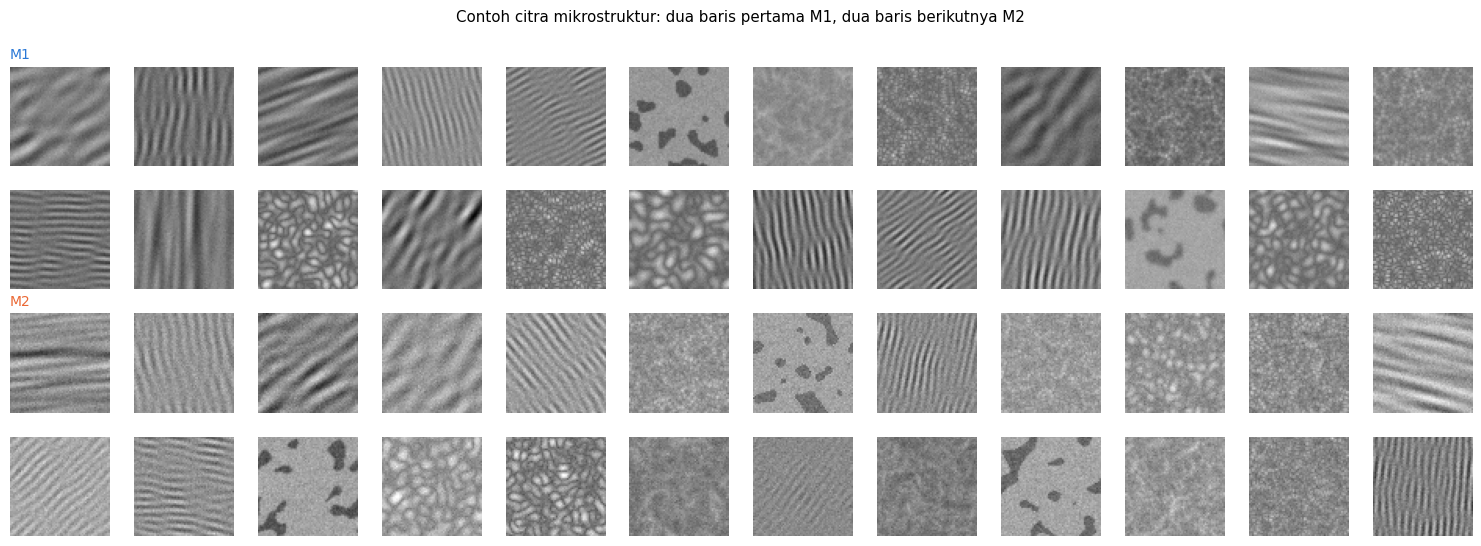

In [23]:
# Contoh citra per mikroskop
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 12, figsize=(15, 5.4))
for r, mic in enumerate(["M1", "M2"]):
    idx = rng.choice(np.where(MIC == mic)[0], 24, replace=False)
    for k, i in enumerate(idx):
        a = axes[r * 2 + k // 12, k % 12]
        a.imshow(G_RAW[i], cmap="gray", vmin=0, vmax=255); a.axis("off")
    axes[r * 2, 0].set_title(mic, loc="left", fontsize=10, color=MIC_COLOR[mic])
fig.suptitle("Contoh citra mikrostruktur: dua baris pertama M1, dua baris berikutnya M2", y=1.0)
plt.tight_layout(); savefig(fig, "t3_eda_images")

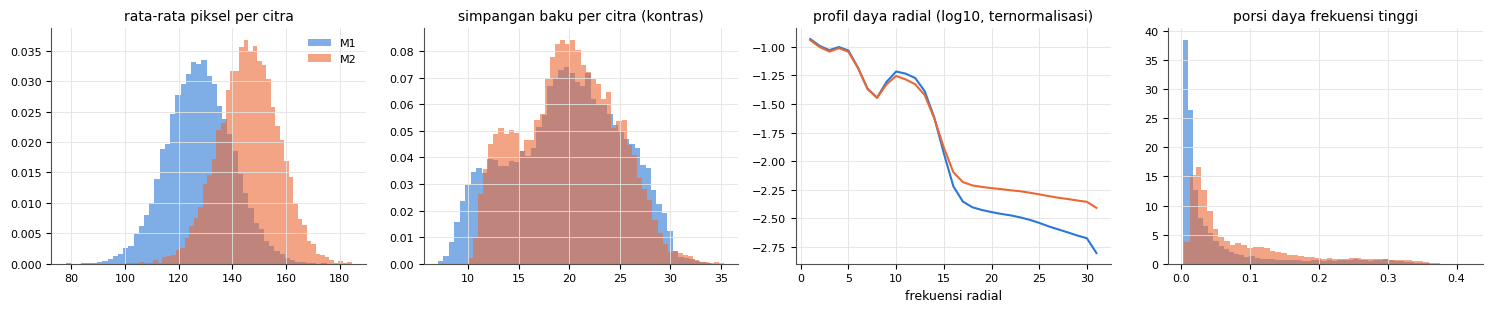

                 M1       M2
mean        127.795  146.068
std_within   19.698   19.902
hf_share      0.051    0.087


In [24]:
# Kecerahan, kontras, dan ketajaman per mikroskop
Gf = G_RAW.astype(np.float32)
img_mean = Gf.mean((1, 2)); img_std = Gf.std((1, 2))
# energi frekuensi tinggi: rasio daya pada radius > 16 terhadap total (tanpa DC)
yy, xx = np.indices((64, 64)); RAD = np.hypot(yy - 32, xx - 32)
RB = np.minimum(RAD.astype(int), 31)                    # bin radial 0..31
R_ASSIGN = np.zeros((4096, 32), np.float32); R_ASSIGN[np.arange(4096), RB.ravel()] = 1.0
R_CNT = R_ASSIGN.sum(0)

def radial_profile(g, chunk=4000):
    out = []
    for i in range(0, len(g), chunk):
        x = g[i:i + chunk]; x = x - x.mean((1, 2), keepdims=True)
        P = np.abs(np.fft.fftshift(np.fft.fft2(x), axes=(1, 2))) ** 2
        out.append((P.reshape(len(x), -1).astype(np.float32) @ R_ASSIGN) / np.maximum(R_CNT, 1))
    return np.concatenate(out)

PROF = radial_profile(Gf)
PROF_N = PROF / PROF[:, 1:].sum(1, keepdims=True)
hf = PROF_N[:, 16:].sum(1)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for mic in ["M1", "M2"]:
    m = MIC == mic
    ax[0].hist(img_mean[m], bins=50, alpha=.6, color=MIC_COLOR[mic], label=mic, density=True)
    ax[1].hist(img_std[m], bins=50, alpha=.6, color=MIC_COLOR[mic], density=True)
    ax[2].plot(np.arange(1, 32), np.log10(PROF_N[m][:, 1:32].mean(0)), color=MIC_COLOR[mic], label=mic)
    ax[3].hist(hf[m], bins=50, alpha=.6, color=MIC_COLOR[mic], density=True)
ax[0].set_title("rata-rata piksel per citra"); ax[0].legend()
ax[1].set_title("simpangan baku per citra (kontras)")
ax[2].set_title("profil daya radial (log10, ternormalisasi)"); ax[2].set_xlabel("frekuensi radial")
ax[3].set_title("porsi daya frekuensi tinggi")
plt.tight_layout(); savefig(fig, "t3_eda_microscope")
RESULTS["eda_image"] = {m: dict(mean=float(img_mean[MIC == m].mean()), std_within=float(img_std[MIC == m].mean()),
                                hf_share=float(hf[MIC == m].mean())) for m in ("M1", "M2")}
print(pd.DataFrame(RESULTS["eda_image"]).round(3).to_string())

citra dengan tekstur berorientasi jelas (koherensi > 0.5): 34.9%


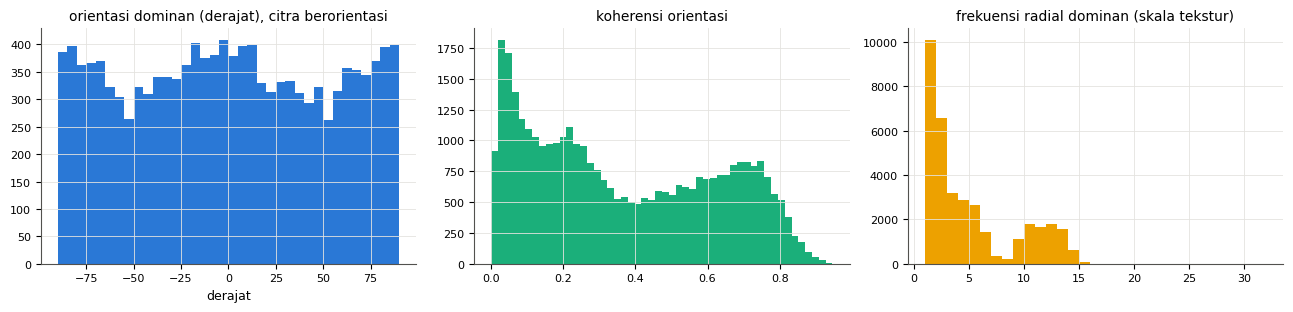

In [25]:
# Rotasi dan skala: orientasi dominan (structure tensor) dan frekuensi radial dominan
def orientation(g, chunk=3000):
    th, coh = [], []
    for i in range(0, len(g), chunk):
        x = g[i:i + chunk]; x = (x - x.mean((1, 2), keepdims=True)) / (x.std((1, 2), keepdims=True) + 1e-6)
        gx = sobel(x, axis=2); gy = sobel(x, axis=1)
        jxx = (gx * gx).sum((1, 2)); jyy = (gy * gy).sum((1, 2)); jxy = (gx * gy).sum((1, 2))
        th.append(0.5 * np.arctan2(2 * jxy, jxx - jyy)); coh.append(np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-9))
    return np.concatenate(th), np.concatenate(coh)

theta, coherence = orientation(Gf)
peak_freq = 1 + PROF_N[:, 1:32].argmax(1)
oriented = coherence > 0.5
print(f"citra dengan tekstur berorientasi jelas (koherensi > 0.5): {oriented.mean():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(np.degrees(theta[oriented]), bins=36, color=SERIES[0])
ax[0].set_title("orientasi dominan (derajat), citra berorientasi"); ax[0].set_xlabel("derajat")
ax[1].hist(coherence, bins=50, color=SERIES[2]); ax[1].set_title("koherensi orientasi")
ax[2].hist(peak_freq, bins=np.arange(1, 33), color=SERIES[3]); ax[2].set_title("frekuensi radial dominan (skala tekstur)")
plt.tight_layout(); savefig(fig, "t3_eda_rotation_scale")
hist_o, _ = np.histogram(theta[oriented], bins=18, range=(-np.pi / 2, np.pi / 2))
RESULTS["eda_image"]["oriented_share"] = float(oriented.mean())
RESULTS["eda_image"]["orientation_hist_max_over_min"] = float(hist_o.max() / max(hist_o.min(), 1))

**Cara membaca.** Histogram orientasi yang rata di semua sudut berarti rotasi acak dan tidak membawa informasi jenis material,
jadi representasi harus invariant terhadap rotasi. Frekuensi radial dominan yang tersebar luas menandakan ada variasi skala tekstur,
sebagian di antaranya kemungkinan membedakan jenis material dan sebagian lagi hanya distorsi skala. Karena itu augmentasi skala dibuat ringan.
Beda kecerahan rata-rata M1 dan M2 diatasi dengan normalisasi per citra. Profil daya radial menunjukkan apakah masih ada beda ketajaman di luar kecerahan.

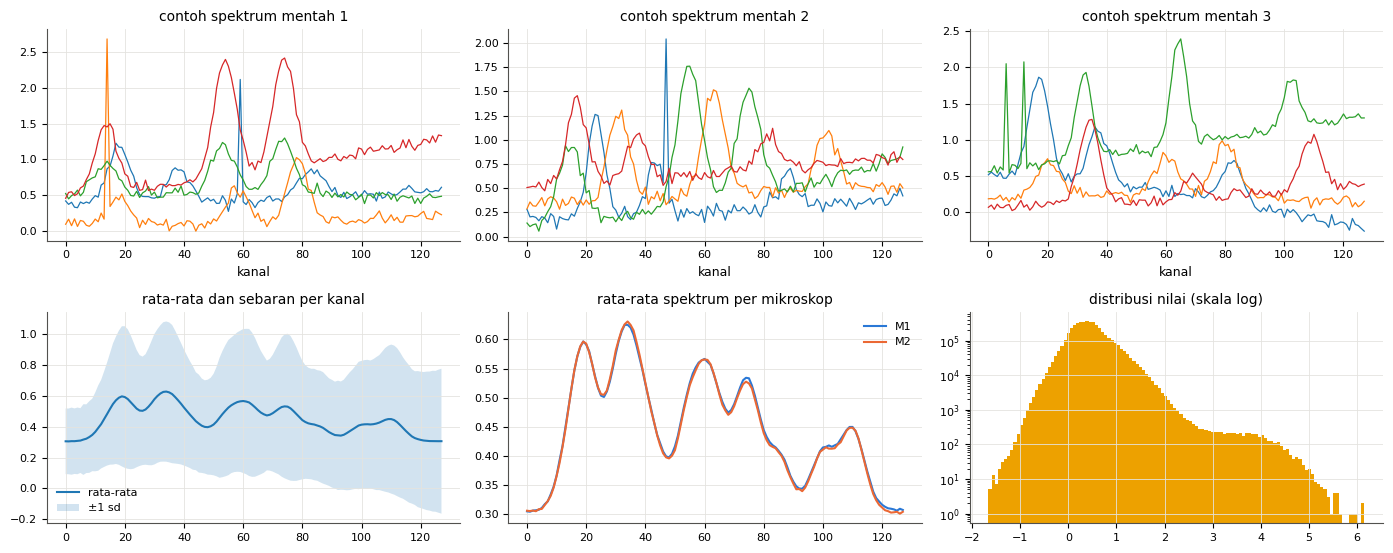

In [26]:
# Spektrum: contoh, baseline, spike, noise, geseran
rng = np.random.default_rng(1)
fig, ax = plt.subplots(2, 3, figsize=(14, 5.6))
for k, i in enumerate(rng.choice(N, 12, replace=False)):
    ax[0, k // 4].plot(S_RAW[i], lw=.9)
for c in range(3): ax[0, c].set_title(f"contoh spektrum mentah {c + 1}"); ax[0, c].set_xlabel("kanal")
sm = S_RAW.mean(0); ss = S_RAW.std(0)
ax[1, 0].plot(sm, label="rata-rata"); ax[1, 0].fill_between(np.arange(128), sm - ss, sm + ss, alpha=.2, label="±1 sd"); ax[1, 0].legend()
ax[1, 0].set_title("rata-rata dan sebaran per kanal")
for mic in ["M1", "M2"]:
    ax[1, 1].plot(S_RAW[MIC == mic].mean(0), color=MIC_COLOR[mic], label=mic)
ax[1, 1].set_title("rata-rata spektrum per mikroskop"); ax[1, 1].legend()
ax[1, 2].hist(S_RAW.ravel(), bins=120, log=True, color=SERIES[3]); ax[1, 2].set_title("distribusi nilai (skala log)")
plt.tight_layout(); savefig(fig, "t3_eda_spectra")

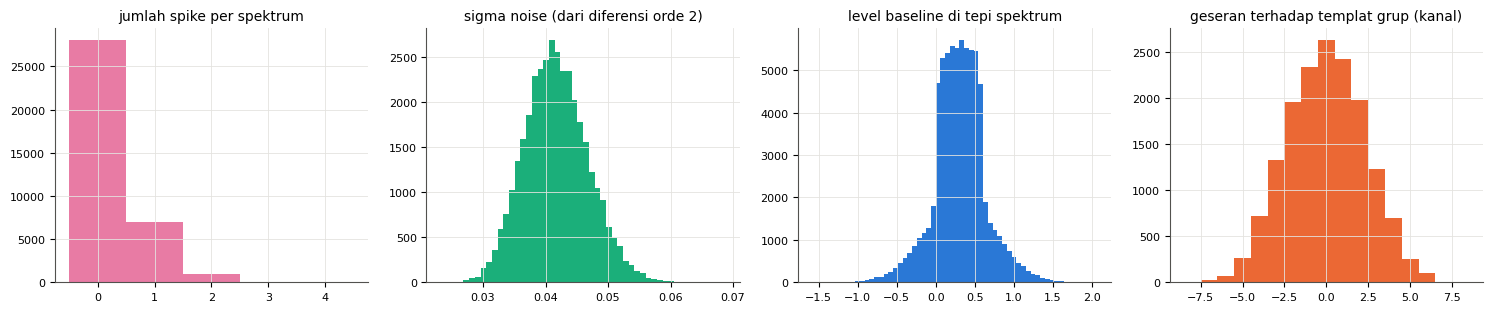

{
 "spike_share": 0.2222222222222222,
 "spikes_mean": 0.2528611111111111,
 "spike_amp_median": 2.46044921875,
 "noise_sigma_median": 0.04152357506956357,
 "baseline_edge_sd": 0.3355611562728882,
 "tilt_sd": 0.39948922395706177,
 "shift_abs_mean": 1.858625,
 "shift_p95": 4.0
}


In [27]:
# Ukur distorsi spektrum secara kuantitatif
d2 = np.diff(S_RAW, n=2, axis=1)
noise_sigma = 1.4826 * np.median(np.abs(d2), axis=1) / np.sqrt(6)      # noise putih: var(d2) = 6 sigma^2, median kebal terhadap spike dan puncak
despiked = median_filter(S_RAW, size=(1, 5), mode="nearest")
resid = S_RAW - despiked
spike_mask = resid > 8 * noise_sigma[:, None]                            # lonjakan positif sempit jauh di atas noise
spike_count = spike_mask.sum(1)
spike_amp = resid[spike_mask]
left = S_RAW[:, :8].mean(1); right = S_RAW[:, -8:].mean(1)        # tepi spektrum ~ baseline murni
tilt = right - left

# geseran: korelasi silang terhadap templat grup kasar (KMeans pada spektrum yang sudah dikoreksi baseline)
def baseline_corrected(s):
    sd = median_filter(s, size=(1, 5), mode="nearest")
    x = sd - median_filter(sd, size=(1, 61), mode="nearest")
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-6)

Xbc = baseline_corrected(S_RAW)
coarse = KMeans(4, n_init=5, random_state=0).fit_predict(PCA(10, random_state=0).fit_transform(Xbc))
lags = np.zeros(N, int); MAXLAG = 8
for g_ in range(4):
    idx = np.where(coarse == g_)[0]; tmpl = np.median(Xbc[idx], 0)
    cc = np.stack([[np.dot(np.roll(Xbc[i], -l), tmpl) for l in range(-MAXLAG, MAXLAG + 1)] for i in idx[:4000]])
    lags[idx[:4000]] = cc.argmax(1) - MAXLAG
lag_used = np.concatenate([lags[np.where(coarse == g_)[0][:4000]] for g_ in range(4)])

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
ax[0].hist(spike_count, bins=np.arange(0, spike_count.max() + 2) - .5, color=SERIES[4]); ax[0].set_title("jumlah spike per spektrum")
ax[1].hist(noise_sigma, bins=50, color=SERIES[2]); ax[1].set_title("sigma noise (dari diferensi orde 2)")
ax[2].hist(np.concatenate([left, right]), bins=60, color=SERIES[0]); ax[2].set_title("level baseline di tepi spektrum")
ax[3].hist(lag_used, bins=np.arange(-MAXLAG, MAXLAG + 2) - .5, color=SERIES[1]); ax[3].set_title("geseran terhadap templat grup (kanal)")
plt.tight_layout(); savefig(fig, "t3_eda_spectrum_distortions")
RESULTS["eda_spectrum"] = dict(spike_share=float((spike_count > 0).mean()), spikes_mean=float(spike_count.mean()),
                               spike_amp_median=float(np.median(spike_amp)) if len(spike_amp) else 0.0,
                               noise_sigma_median=float(np.median(noise_sigma)), baseline_edge_sd=float(np.concatenate([left, right]).std()),
                               tilt_sd=float(tilt.std()), shift_abs_mean=float(np.abs(lag_used).mean()),
                               shift_p95=float(np.percentile(np.abs(lag_used), 95)))
print(json.dumps(RESULTS["eda_spectrum"], indent=1))

**Cara membaca.** Spike muncul sebagai pencilan sempit dan dibuang dengan median filter berjendela 5 kanal (puncak spektrum jauh lebih lebar).
Level di tepi spektrum seharusnya hampir sama untuk semua sampel bila tidak ada baseline. Sebaran yang lebar berarti ada offset dan kemiringan baseline,
yang dikoreksi dengan pengurangan median berjendela 61 kanal. Histogram geseran memberi batas atas besarnya pergeseran puncak
(sebagian geseran ini adalah variasi komposisi asli), dan nilainya dipakai untuk menentukan geseran maksimum pada augmentasi spektrum.

## 3. Praproses dan augmentasi (butir b)

**Praproses (deterministik, tanpa label)**

| Modalitas | Langkah | Alasan |
|---|---|---|
| Citra | standardisasi per citra (rata-rata 0, sd 1) | menghilangkan beda kecerahan dan kontras, termasuk offset M1 dan M2 |
| Spektrum | median filter 5 kanal, kurangi median 61 kanal, normalisasi L2 | membuang spike, baseline, dan skala global; bentuk puncak tetap |

**Augmentasi untuk pembelajaran kontrastif.** Dua tampilan acak dari sampel yang sama dianggap pasangan positif, jadi setiap augmentasi
mengajarkan encoder untuk mengabaikan distorsi itu. Augmentasi dipilih hanya dari distorsi yang disebut di soal, supaya tidak menghapus
ciri yang membedakan material.

| Modalitas | Augmentasi | Mengapa |
|---|---|---|
| Citra | rotasi 0 sampai 360 derajat dan flip | orientasi tekstur acak, bukan ciri material |
| Citra | skala 0.8 sampai 1.25, geser 10% | skala hanya diubah ringan karena sebagian skala tekstur membedakan material |
| Citra | gamma, blur, noise | beda kecerahan dan ketajaman antar mikroskop |
| Spektrum | geser fraksional hingga ±4 kanal | pergeseran kalibrasi |
| Spektrum | baseline acak (offset, miring, lengkung) | sisa baseline setelah koreksi median |
| Spektrum | spike acak, noise, skala amplitudo | spike, noise, dan variasi intensitas |

Seluruh augmentasi berjalan di GPU supaya satu epoch cepat.

In [28]:
def preprocess_spectrum(s):
    sd = median_filter(s, size=(1, 5), mode="nearest")
    x = sd - median_filter(sd, size=(1, 61), mode="nearest")
    return (x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-6) * 10.0).astype(np.float32)

def standardize_img(x):
    return (x - x.mean((1, 2, 3), keepdim=True)) / (x.std((1, 2, 3), keepdim=True) + 1e-4)

@torch.no_grad()
def aug_image(x, rot=True, scale=(0.8, 1.25), shift=0.1):
    """x: (B,1,64,64) di GPU, rentang [0,1]. Mengembalikan batch teraugmentasi yang sudah distandardisasi per citra."""
    B = x.shape[0]; d = x.device
    th = torch.rand(B, device=d) * 2 * math.pi if rot else torch.zeros(B, device=d)
    sc = torch.exp(torch.empty(B, device=d).uniform_(math.log(scale[0]), math.log(scale[1])))
    flip = (torch.rand(B, device=d) < 0.5).float() * 2 - 1
    c, s = torch.cos(th) / sc, torch.sin(th) / sc
    A = torch.zeros(B, 2, 3, device=d)
    A[:, 0, 0] = c * flip; A[:, 0, 1] = -s; A[:, 1, 0] = s * flip; A[:, 1, 1] = c
    A[:, :, 2] = torch.empty(B, 2, device=d).uniform_(-shift, shift)
    grid = F.affine_grid(A, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    gam = torch.exp(torch.empty(B, 1, 1, 1, device=d).uniform_(-0.35, 0.35))
    x = x.clamp(1e-3, 1) ** gam
    sig = torch.rand(B, device=d) * 1.0
    k = torch.arange(-3, 4, device=d).float()
    ker = torch.exp(-k[None] ** 2 / (2 * (sig[:, None] ** 2 + 1e-3))); ker = ker / ker.sum(1, keepdim=True)
    xb = F.conv2d(F.pad(x, (3, 3, 0, 0), mode="reflect").reshape(1, B, 64, 70), ker[:, None, None, :], groups=B).reshape(B, 1, 64, 64)
    xb = F.conv2d(F.pad(xb, (0, 0, 3, 3), mode="reflect").reshape(1, B, 70, 64), ker[:, None, :, None], groups=B).reshape(B, 1, 64, 64)
    x = torch.where(torch.rand(B, 1, 1, 1, device=d) < 0.5, xb, x)
    x = x + torch.randn_like(x) * torch.rand(B, 1, 1, 1, device=d) * 0.03
    return standardize_img(x)

@torch.no_grad()
def aug_spec(x, max_shift=4.0):
    """x: (B,128) spektrum terpraproses di GPU."""
    B, L = x.shape; d = x.device
    sh = torch.empty(B, 1, device=d).uniform_(-max_shift, max_shift)
    pos = torch.arange(L, device=d).float()[None] - sh
    p0 = pos.floor().clamp(0, L - 2); w = (pos - p0).clamp(0, 1); p0 = p0.long()
    x = x.gather(1, p0) * (1 - w) + x.gather(1, p0 + 1) * w
    t = torch.linspace(-1, 1, L, device=d)[None]
    base = torch.randn(B, 1, device=d) * 0.15 + torch.randn(B, 1, device=d) * 0.2 * t + torch.randn(B, 1, device=d) * 0.2 * (t ** 2 - 0.33)
    x = x + base * (torch.rand(B, 1, device=d) < 0.8)
    has_spike = torch.rand(B, 1, device=d) < 0.3        # di data asli ~22% spektrum punya satu spike (lihat bagian 2)
    idx = torch.randint(0, L, (B,), device=d)
    x = x + F.one_hot(idx, L).float() * has_spike * torch.empty(B, 1, device=d).uniform_(1, 5)
    x = x * torch.exp(torch.randn(B, 1, device=d) * 0.1)
    return x + torch.randn_like(x) * 0.05

# data di GPU
S_PRE = preprocess_spectrum(S_RAW)
XI = torch.as_tensor(G_RAW, device=DEV).float().div(255).unsqueeze(1)     # (N,1,64,64) [0,1], dasar augmentasi
EI = standardize_img(XI)                                                  # citra tanpa augmentasi (untuk ekstraksi embedding)
XS = torch.as_tensor(S_PRE, device=DEV)
print("citra", tuple(XI.shape), "| spektrum", tuple(XS.shape), "| memori GPU:",
      f"{torch.cuda.memory_allocated() / 1e9:.2f} GB" if DEV.type == "cuda" else "cpu")

citra (36000, 1, 64, 64) | spektrum (36000, 128) | memori GPU: 2.74 GB


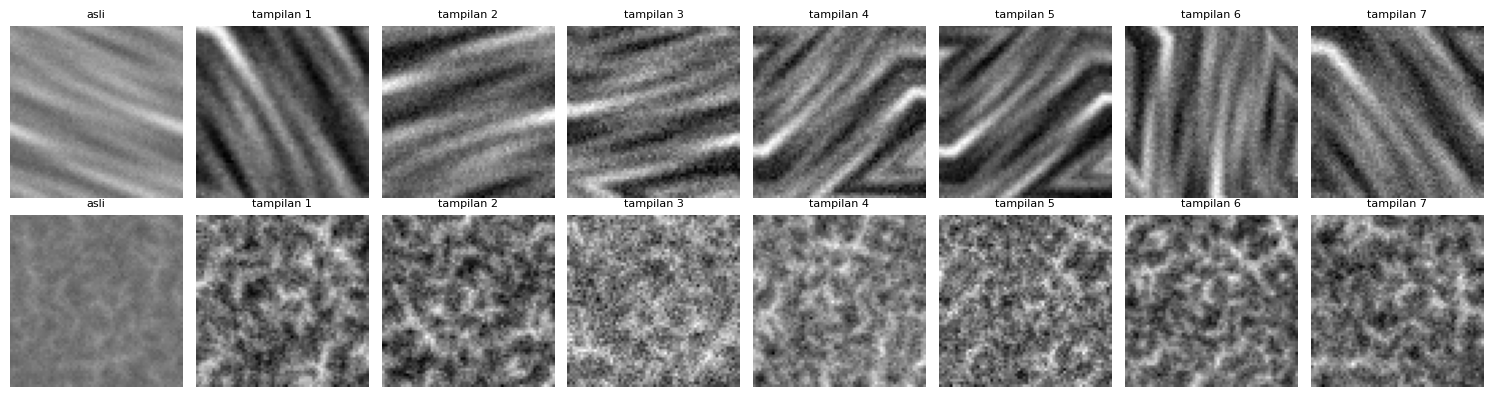

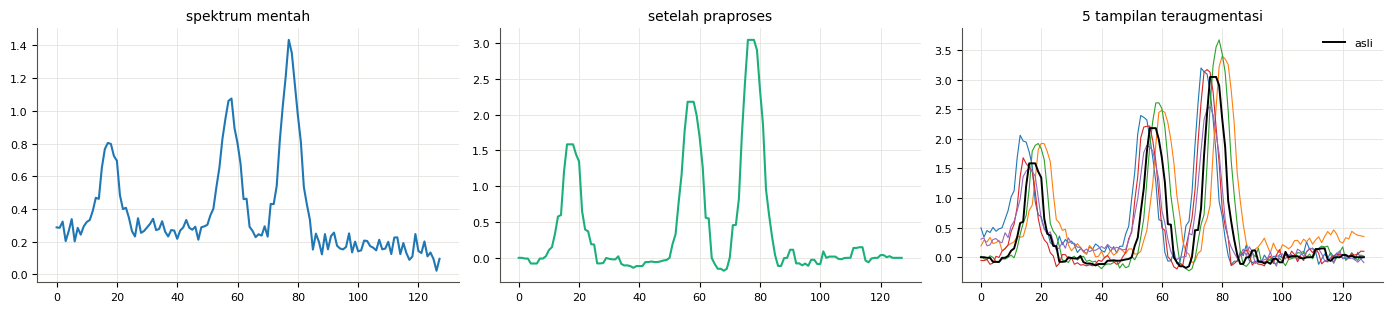

In [29]:
# Tampilkan efek praproses dan augmentasi
set_seed(0)
i0 = int(np.where(oriented)[0][0]); i1 = int(np.where(~oriented)[0][0])
fig, ax = plt.subplots(2, 8, figsize=(15, 4))
for r, i in enumerate([i0, i1]):
    ax[r, 0].imshow(G_RAW[i], cmap="gray", vmin=0, vmax=255); ax[r, 0].set_title("asli", fontsize=8)
    views = aug_image(XI[i:i + 1].repeat(7, 1, 1, 1)).cpu().numpy()[:, 0]
    for k in range(7):
        ax[r, k + 1].imshow(views[k], cmap="gray"); ax[r, k + 1].set_title(f"tampilan {k + 1}", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); savefig(fig, "t3_aug_images")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
i = int(rng.choice(N))
ax[0].plot(S_RAW[i], label="mentah"); ax[0].set_title("spektrum mentah")
ax[1].plot(S_PRE[i], color=SERIES[2]); ax[1].set_title("setelah praproses")
v = aug_spec(XS[i:i + 1].repeat(5, 1)).cpu().numpy()
for k in range(5): ax[2].plot(v[k], lw=.8)
ax[2].plot(S_PRE[i], color="k", lw=1.4, label="asli"); ax[2].legend(); ax[2].set_title("5 tampilan teraugmentasi")
plt.tight_layout(); savefig(fig, "t3_aug_spectra")

## 4. Representasi tanpa label (butir b)

Dua encoder dilatih terpisah dengan SimCLR (loss NT-Xent, suhu 0,2):

* **Encoder citra:** ResNet kecil (stem stride 2, empat blok residual, lebar 32 sampai 256, global average pooling), keluaran 256 dimensi.
* **Encoder spektrum:** CNN 1D enam lapis (kernel 7, tiga downsampling), lalu satu lapis linear dari peta fitur yang diratakan.
  Posisi kanal dipertahankan karena posisi puncak adalah ciri utama spektrum, jadi tidak memakai global pooling.

Embedding untuk clustering diambil dari keluaran encoder (sebelum projection head), cara standar SimCLR.
Checkpoint disimpan di `OUT_DIR/checkpoints`. Bila sel dijalankan ulang dan checkpoint ada, pelatihan dilewati (set `FORCE_RETRAIN = True` untuk melatih ulang).

In [30]:
class Block(nn.Module):
    def __init__(s, i, o, stride):
        super().__init__()
        s.c1 = nn.Conv2d(i, o, 3, stride, 1, bias=False); s.b1 = nn.BatchNorm2d(o)
        s.c2 = nn.Conv2d(o, o, 3, 1, 1, bias=False); s.b2 = nn.BatchNorm2d(o)
        s.sk = None if (i == o and stride == 1) else nn.Sequential(nn.Conv2d(i, o, 1, stride, bias=False), nn.BatchNorm2d(o))
    def forward(s, x):
        y = F.relu(s.b1(s.c1(x))); y = s.b2(s.c2(y))
        return F.relu(y + (x if s.sk is None else s.sk(x)))

class ImgEncoder(nn.Module):
    out_dim = 256
    def __init__(s, w=(32, 64, 128, 256)):
        super().__init__()
        s.stem = nn.Sequential(nn.Conv2d(1, w[0], 3, 2, 1, bias=False), nn.BatchNorm2d(w[0]), nn.ReLU())
        s.layers = nn.Sequential(Block(w[0], w[1], 1), Block(w[1], w[2], 2), Block(w[2], w[3], 2), Block(w[3], w[3], 2))
    def forward(s, x):
        return s.layers(s.stem(x)).mean((2, 3))

class SpecEncoder(nn.Module):
    out_dim = 256
    def __init__(s):
        super().__init__()
        def cb(i, o, st): return nn.Sequential(nn.Conv1d(i, o, 7, st, 3, bias=False), nn.BatchNorm1d(o), nn.ReLU())
        s.net = nn.Sequential(cb(1, 32, 1), cb(32, 64, 2), cb(64, 64, 1), cb(64, 128, 2), cb(128, 128, 1), cb(128, 128, 2))  # 128 -> 16
        s.fc = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 256), nn.BatchNorm1d(256), nn.ReLU())
    def forward(s, x):
        return s.fc(s.net(x.unsqueeze(1)))

def proj(i, h=256, o=128):
    return nn.Sequential(nn.Linear(i, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Linear(h, o))

def nt_xent(z1, z2, T=0.2):
    # dihitung dalam float32: di dalam autocast fp16, matmul menjadi half dan -1e9 melampaui batas fp16 (65504)
    with torch.autocast(device_type=DEV.type, enabled=False):
        z = F.normalize(torch.cat([z1, z2]).float(), dim=1); n = z1.shape[0]
        sim = z @ z.T / T; sim.fill_diagonal_(-1e9)
        tgt = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
        return F.cross_entropy(sim, tgt)

def set_lr(opt, bases, step, total, warm=100):
    f = min(1, (step + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1, step / total)))
    for g, b in zip(opt.param_groups, bases):
        g["lr"] = b * f

@torch.no_grad()
def embed(enc, X, bs=1000):
    enc.eval(); out = []
    for i in range(0, len(X), bs):
        with amp():
            out.append(enc(X[i:i + bs]).float().cpu())
    return torch.cat(out).numpy()

def train_simclr(kind, X, epochs, seed, bs=BATCH, lr=1e-3):
    set_seed(seed)
    enc = (ImgEncoder() if kind == "img" else SpecEncoder()).to(DEV); head = proj(enc.out_dim).to(DEV)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(head.parameters()), lr=lr, weight_decay=1e-4)
    scaler = new_scaler(); aug = aug_image if kind == "img" else aug_spec
    nb = len(X) // bs; steps = epochs * nb; step = 0; hist = []; t0 = time.time()
    for ep in range(epochs):
        enc.train(); head.train(); perm = torch.randperm(len(X), device=DEV); tot = 0
        for i in range(nb):
            xb = X[perm[i * bs:(i + 1) * bs]]
            set_lr(opt, [lr], step, steps); step += 1
            with amp():
                z1 = head(enc(aug(xb))); z2 = head(enc(aug(xb)))
            loss = nt_xent(z1, z2)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        hist.append(tot / nb)
        if ep % 5 == 0 or ep == epochs - 1:
            print(f"[{kind} seed {seed}] epoch {ep + 1}/{epochs}  loss {hist[-1]:.4f}  ({time.time() - t0:.0f}s)")
    return enc, hist

def get_ssl(kind, seed):
    """Latih (atau muat dari checkpoint) encoder SimCLR. Mengembalikan encoder, embedding, riwayat loss."""
    X = XI if kind == "img" else XS; E = EI if kind == "img" else XS
    p = CKPT_DIR / f"enc_{kind}_s{seed}.pt"
    enc = (ImgEncoder() if kind == "img" else SpecEncoder()).to(DEV)
    if p.exists() and not FORCE_RETRAIN:
        ck = torch.load(p, map_location=DEV); enc.load_state_dict(ck["state"]); hist = ck["hist"]
        print(f"[{kind} seed {seed}] checkpoint dimuat: {p.name}")
    else:
        enc, hist = train_simclr(kind, X, EPOCHS[kind], seed)
        torch.save(dict(state=enc.state_dict(), hist=hist, epochs=EPOCHS[kind]), p)
    return enc, embed(enc, E), hist

[spec seed 0] checkpoint dimuat: enc_spec_s0.pt
[img seed 0] checkpoint dimuat: enc_img_s0.pt


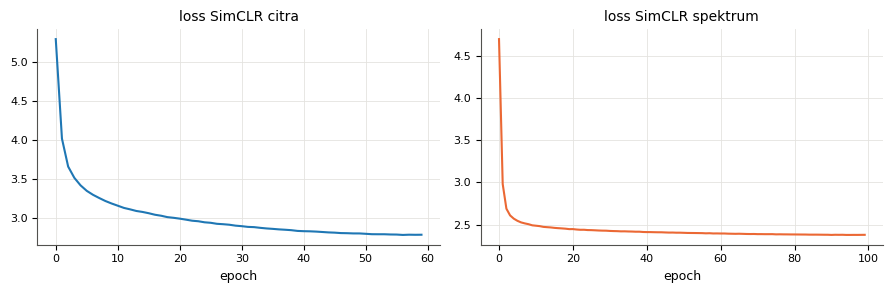

In [31]:
ENC_SPEC, Z_SPEC, H_SPEC = get_ssl("spec", MAIN_SEED)
ENC_IMG, Z_IMG, H_IMG = get_ssl("img", MAIN_SEED)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(H_IMG); ax[0].set_title("loss SimCLR citra"); ax[0].set_xlabel("epoch")
ax[1].plot(H_SPEC, color=SERIES[1]); ax[1].set_title("loss SimCLR spektrum"); ax[1].set_xlabel("epoch")
plt.tight_layout(); savefig(fig, "t3_simclr_loss")
RESULTS["simclr"] = dict(epochs=EPOCHS, final_loss_img=float(H_IMG[-1]), final_loss_spec=float(H_SPEC[-1]), batch=BATCH,
                         amp=str(AMP_DTYPE), seed=MAIN_SEED)

## 5. Fusi dua modalitas (butir c)

Tidak ada label, jadi kualitas embedding diukur dengan diagnostik yang tidak memakai label:

* **Silhouette dan Davies-Bouldin** dari KMeans pada beberapa nilai K (seberapa terpisah struktur yang ditemukan).
* **Kebocoran mikroskop:** akurasi regresi logistik yang menebak M1/M2 dari embedding. Nilai mendekati proporsi kelas mayoritas
  berarti embedding tidak memuat informasi mikroskop. Itu yang diinginkan karena mikroskop adalah distorsi, bukan jenis material.
* **Kesepakatan antar modalitas:** ARI antara clustering citra saja dan spektrum saja. Bila keduanya menangkap jenis material yang sama, ARI-nya naik.
* **Tumpang tindih tetangga:** seberapa besar k-tetangga terdekat pada embedding fusi juga muncul pada embedding satu modalitas.

Dua strategi fusi dibandingkan, ditambah dua baseline satu modalitas:

| Nama | Cara |
|---|---|
| `img`, `spec` | embedding satu modalitas (baseline untuk melihat apa yang hilang) |
| `concat` | fusi tingkat fitur: tiap embedding diterapkan PCA 32 dimensi, diskalakan ke total varians 1, lalu digabung |
| `joint` | fusi yang dipelajari: kedua encoder dilatih lanjut bersama MLP fusi. Loss = NT-Xent pada embedding fusi dua tampilan + loss kontrastif lintas modalitas (citra dan spektrum dari sampel yang sama sebagai pasangan positif) |

Loss lintas modalitas memaksa encoder mempertahankan hal yang dibagi kedua modalitas, yaitu jenis material,
dan mengabaikan variasi yang hanya ada di salah satunya.

In [32]:
class FusionHead(nn.Module):
    """Fusi tingkat fitur: gabungkan fitur backbone lalu MLP menjadi embedding fusi."""
    def __init__(s, di=256, ds=256, h=256):
        super().__init__()
        s.mlp = nn.Sequential(nn.Linear(di + ds, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Linear(h, h), nn.BatchNorm1d(h), nn.ReLU())
        s.proj = proj(h)
    def forward(s, fi, fs):
        return s.mlp(torch.cat([fi, fs], 1))

def clip_loss(a, b, T=0.2):
    with torch.autocast(device_type=DEV.type, enabled=False):   # float32, lihat catatan di nt_xent
        a = F.normalize(a.float(), dim=1); b = F.normalize(b.float(), dim=1)
        lg = a @ b.T / T; t = torch.arange(len(a), device=a.device)
        return 0.5 * (F.cross_entropy(lg, t) + F.cross_entropy(lg.T, t))

def train_joint(enc_i, enc_s, epochs, seed, lam=1.0, bs=BATCH, lr=1e-3, enc_lr=3e-4):
    set_seed(seed)
    head = FusionHead().to(DEV); pi = proj(256).to(DEV); ps = proj(256).to(DEV)
    opt = torch.optim.AdamW([dict(params=list(enc_i.parameters()) + list(enc_s.parameters()), lr=enc_lr),
                             dict(params=list(head.parameters()) + list(pi.parameters()) + list(ps.parameters()), lr=lr)], weight_decay=1e-4)
    scaler = new_scaler(); bases = [enc_lr, lr]; nb = len(XI) // bs; steps = epochs * nb; step = 0; hist = []; t0 = time.time()
    for ep in range(epochs):
        for m in (enc_i, enc_s, head, pi, ps): m.train()
        perm = torch.randperm(len(XI), device=DEV); tot = 0
        for i in range(nb):
            ix = perm[i * bs:(i + 1) * bs]; xi = XI[ix]; xs = XS[ix]
            set_lr(opt, bases, step, steps); step += 1
            with amp():
                fi1, fi2 = enc_i(aug_image(xi)), enc_i(aug_image(xi)); fs1, fs2 = enc_s(aug_spec(xs)), enc_s(aug_spec(xs))
                h1, h2 = head(fi1, fs1), head(fi2, fs2)
                l_fuse = nt_xent(head.proj(h1), head.proj(h2))
                l_cross = 0.5 * (clip_loss(pi(fi1), ps(fs1)) + clip_loss(pi(fi2), ps(fs2)))
            loss = l_fuse + lam * l_cross
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        hist.append(tot / nb)
        if ep % 2 == 0 or ep == epochs - 1:
            print(f"[joint seed {seed}] epoch {ep + 1}/{epochs}  loss {hist[-1]:.4f}  ({time.time() - t0:.0f}s)")
    return head, hist

@torch.no_grad()
def embed_joint(enc_i, enc_s, head, bs=1000):
    for m in (enc_i, enc_s, head): m.eval()
    out = []
    for i in range(0, N, bs):
        with amp():
            out.append(head(enc_i(EI[i:i + bs]), enc_s(XS[i:i + bs])).float().cpu())
    return torch.cat(out).numpy()

def get_joint(seed, enc_i0, enc_s0):
    import copy
    p = CKPT_DIR / f"joint_s{seed}.pt"
    enc_i, enc_s, head = copy.deepcopy(enc_i0), copy.deepcopy(enc_s0), FusionHead().to(DEV)
    if p.exists() and not FORCE_RETRAIN:
        ck = torch.load(p, map_location=DEV)
        enc_i.load_state_dict(ck["enc_i"]); enc_s.load_state_dict(ck["enc_s"]); head.load_state_dict(ck["head"]); hist = ck["hist"]
        print(f"[joint seed {seed}] checkpoint dimuat: {p.name}")
    else:
        head, hist = train_joint(enc_i, enc_s, EPOCHS["joint"], seed)
        torch.save(dict(enc_i=enc_i.state_dict(), enc_s=enc_s.state_dict(), head=head.state_dict(), hist=hist), p)
    return embed_joint(enc_i, enc_s, head), hist

Z_JOINT, H_JOINT = get_joint(MAIN_SEED, ENC_IMG, ENC_SPEC)
RESULTS["joint"] = dict(epochs=EPOCHS["joint"], final_loss=float(H_JOINT[-1]))

[joint seed 0] epoch 1/20  loss 8.1231  (14s)
[joint seed 0] epoch 3/20  loss 7.2833  (42s)
[joint seed 0] epoch 5/20  loss 7.2517  (69s)
[joint seed 0] epoch 7/20  loss 7.2361  (97s)
[joint seed 0] epoch 9/20  loss 7.2219  (124s)
[joint seed 0] epoch 11/20  loss 7.2115  (152s)
[joint seed 0] epoch 13/20  loss 7.2023  (180s)
[joint seed 0] epoch 15/20  loss 7.1918  (207s)
[joint seed 0] epoch 17/20  loss 7.1820  (235s)
[joint seed 0] epoch 19/20  loss 7.1748  (262s)
[joint seed 0] epoch 20/20  loss 7.1735  (276s)


In [33]:
def reduce(Z, n=32, seed=0):
    """standardisasi per dimensi, PCA, lalu skala ke total varians 1 (supaya modalitas sebanding saat digabung)."""
    Zs = (Z - Z.mean(0)) / (Z.std(0) + 1e-6)
    P = PCA(min(n, Z.shape[1]), random_state=seed).fit_transform(Zs)
    return (P / np.sqrt(P.var(0).sum())).astype(np.float32)

EMB = {"img": reduce(Z_IMG), "spec": reduce(Z_SPEC), "joint": reduce(Z_JOINT)}
EMB["concat"] = np.hstack([EMB["img"], EMB["spec"]]).astype(np.float32)
SIL_IDX = np.random.default_rng(0).choice(N, min(8000, N), replace=False)

def kscan(X, ks, seed=0):
    rows = []
    for k in ks:
        km = KMeans(k, n_init=5, random_state=seed).fit(X)
        rows.append(dict(k=k, silhouette=silhouette_score(X[SIL_IDX], km.labels_[SIL_IDX]), davies_bouldin=davies_bouldin_score(X, km.labels_),
                         calinski_harabasz=calinski_harabasz_score(X, km.labels_)))
    return pd.DataFrame(rows)

def leakage(X, seed=0):
    y = (MIC == "M2").astype(int); idx = np.random.default_rng(seed).choice(N, min(8000, N), replace=False)
    acc = cross_val_score(LogisticRegression(max_iter=500), X[idx], y[idx], cv=3).mean()
    return float(acc), float(max(y.mean(), 1 - y.mean()))

def knn_idx(X, k=15):
    return NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]

def knn_overlap(a, b):
    return float(np.mean([len(set(a[i]) & set(b[i])) / a.shape[1] for i in range(len(a))]))

SCAN = {name: kscan(X, K_RANGE) for name, X in EMB.items()}
KNN = {name: knn_idx(X) for name, X in EMB.items()}
rows = []
for name, X in EMB.items():
    df = SCAN[name]; best = df.loc[df.silhouette.idxmax()]; acc, maj = leakage(X)
    rows.append(dict(embedding=name, dim=X.shape[1], best_k_sil=int(best.k), sil_at_best=best.silhouette, db_at_best=best.davies_bouldin,
                     leak_acc=acc, leak_majority=maj, knn_overlap_img=knn_overlap(KNN[name], KNN["img"]), knn_overlap_spec=knn_overlap(KNN[name], KNN["spec"])))
FUSION_TABLE = pd.DataFrame(rows).set_index("embedding")
print(FUSION_TABLE.round(3).to_string())

# kesepakatan antar modalitas, dan apa yang hilang bila hanya satu modalitas dipakai
agree = []
for k in [k for k in (3, 4, 6, 8, 10, 12) if k in K_RANGE] or K_RANGE[-2:]:
    lab = {n_: KMeans(k, n_init=5, random_state=0).fit_predict(EMB[n_]) for n_ in EMB}
    agree.append(dict(k=k, img_vs_spec=adjusted_rand_score(lab["img"], lab["spec"]),
                      img_vs_concat=adjusted_rand_score(lab["img"], lab["concat"]), spec_vs_concat=adjusted_rand_score(lab["spec"], lab["concat"]),
                      img_vs_joint=adjusted_rand_score(lab["img"], lab["joint"]), spec_vs_joint=adjusted_rand_score(lab["spec"], lab["joint"]),
                      concat_vs_joint=adjusted_rand_score(lab["concat"], lab["joint"])))
AGREE = pd.DataFrame(agree).set_index("k")
print("\nARI antar clustering (KMeans, K sama):"); print(AGREE.round(3).to_string())
RESULTS["fusion_table"] = FUSION_TABLE.round(4).reset_index().to_dict("records")
RESULTS["agreement_ari"] = AGREE.round(4).reset_index().to_dict("records")

           dim  best_k_sil  sil_at_best  db_at_best  leak_acc  leak_majority  knn_overlap_img  knn_overlap_spec
embedding                                                                                                      
img         32           6        0.318       1.251     0.694          0.601            1.000             0.002
spec        32           4        0.324       1.371     0.600          0.601            0.002             1.000
joint       32          15        0.254       1.482     0.599          0.601            0.005             0.470
concat      64           5        0.320       1.275     0.702          0.601            0.105             0.094

ARI antar clustering (KMeans, K sama):
    img_vs_spec  img_vs_concat  spec_vs_concat  img_vs_joint  spec_vs_joint  concat_vs_joint
k                                                                                           
3         0.411          0.783           0.626         0.411          1.000            0.626
4        

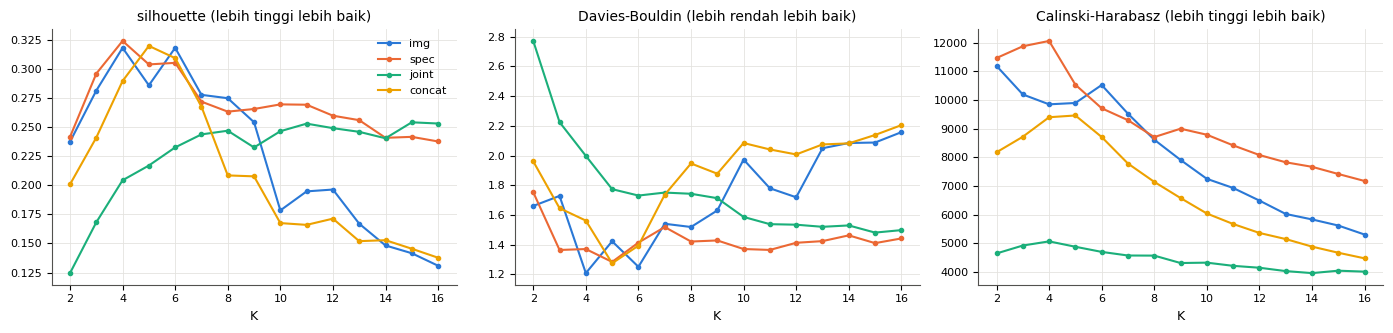

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for j, (col, ttl) in enumerate([("silhouette", "silhouette (lebih tinggi lebih baik)"), ("davies_bouldin", "Davies-Bouldin (lebih rendah lebih baik)"),
                                ("calinski_harabasz", "Calinski-Harabasz (lebih tinggi lebih baik)")]):
    for c, name in zip(SERIES, EMB):
        ax[j].plot(SCAN[name].k, SCAN[name][col], marker="o", ms=3, color=c, label=name)
    ax[j].set_title(ttl); ax[j].set_xlabel("K")
ax[0].legend(); plt.tight_layout(); savefig(fig, "t3_fusion_kscan")

In [35]:
# Pilih embedding fusi yang dipakai untuk clustering: aturan = silhouette terbaik di antara dua strategi fusi (bisa diganti lewat FUSION)
if FUSION is None:
    FUSION_CHOICE = max(("concat", "joint"), key=lambda n_: FUSION_TABLE.loc[n_, "sil_at_best"])
else:
    FUSION_CHOICE = FUSION
X = EMB[FUSION_CHOICE]
print("embedding fusi terpilih:", FUSION_CHOICE, "| dimensi", X.shape)
RESULTS["fusion_choice"] = FUSION_CHOICE

embedding fusi terpilih: concat | dimensi (36000, 64)


## 6. Metode clustering (butir d)

Empat metode dijalankan pada embedding fusi terpilih:

| Metode | Jenis | Catatan |
|---|---|---|
| KMeans | partisi, centroid | `n_init=10` |
| GMM | model campuran, kovarians penuh | tahan terhadap cluster yang tidak bulat |
| Agglomerative (Ward) | hierarki | memakai graf 30 tetangga terdekat sebagai konektivitas supaya muat untuk 36.000 titik |
| Graph bisection | pembelahan graf kNN | mulai dari komponen terhubung, lalu membelah bagian dengan leher botol terkecil (eigenvalue Fiedler) sampai K. Memotong di celah antar kelompok, bukan di tengah blob yang besar |
| **DEC** | **deep clustering** | autoencoder pada embedding (dimensi laten 10), inisialisasi KMeans, lalu minimasi KL antara distribusi Student-t dan distribusi target yang dipertajam. Berhenti bila perubahan label < 0,1% |

Jumlah cluster K ditentukan lebih dulu pada bagian 7, jadi definisi metode dan fungsi bantu ditulis di sini dan metodenya dijalankan setelah K ketemu (bagian 7b).

In [36]:
class DECNet(nn.Module):
    def __init__(s, din, dz, k):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(din, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, dz))
        s.dec = nn.Sequential(nn.Linear(dz, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, din))
        s.mu = nn.Parameter(torch.zeros(k, dz))
    def q(s, z, alpha=1.0):
        d2 = torch.cdist(z, s.mu) ** 2; q = (1 + d2 / alpha) ** (-(alpha + 1) / 2)
        return q / q.sum(1, keepdim=True)

def run_dec(Xin, k, seed=0, ae_epochs=None, dec_iters=None, bs=1024, tol=1e-3):
    ae_epochs = ae_epochs or EPOCHS["ae"]; dec_iters = dec_iters or EPOCHS["dec"]
    set_seed(seed)
    Xt = torch.as_tensor(Xin * np.sqrt(Xin.shape[1]), dtype=torch.float32, device=DEV); n = len(Xt)   # varians rata-rata per dimensi = 1
    net = DECNet(Xt.shape[1], 10, k).to(DEV)
    opt = torch.optim.Adam(list(net.enc.parameters()) + list(net.dec.parameters()), 1e-3)
    for ep in range(ae_epochs):
        perm = torch.randperm(n, device=DEV)
        for i in range(0, n, bs):
            xb = Xt[perm[i:i + bs]]; loss = F.mse_loss(net.dec(net.enc(xb)), xb)
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        Z0 = net.enc(Xt).cpu().numpy()
    km = KMeans(k, n_init=10, random_state=seed).fit(Z0)
    net.mu.data = torch.tensor(km.cluster_centers_, dtype=torch.float32, device=DEV)
    prev = km.labels_.copy(); opt = torch.optim.Adam(net.parameters(), 1e-4); changes = []
    for it in range(dec_iters):
        with torch.no_grad():
            q = net.q(net.enc(Xt)); p = q ** 2 / q.sum(0); p = p / p.sum(1, keepdim=True); lab = q.argmax(1).cpu().numpy()
        changes.append(float((lab != prev).mean())); prev = lab
        if it > 0 and changes[-1] < tol:
            break
        perm = torch.randperm(n, device=DEV)
        for i in range(0, n, bs):
            ix = perm[i:i + bs]; z = net.enc(Xt[ix]); qb = net.q(z)
            loss = F.kl_div(qb.clamp_min(1e-8).log(), p[ix], reduction="batchmean") + 0.1 * F.mse_loss(net.dec(z), Xt[ix])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        lab = net.q(net.enc(Xt)).argmax(1).cpu().numpy()
    return lab, changes

def graph_bisection_labels(Xin, K, seed=0, nn=15):
    """Pembelahan graf kNN bertahap. Mulai dari komponen terhubung, lalu terus membelah bagian yang punya leher botol terkecil
    (eigenvalue Fiedler terkecil dari Laplacian ternormalisasi) sampai ada K bagian. Cocok untuk kelompok yang terpisah atau
    hanya terhubung tipis, dan tidak memotong blob kontinu yang sekadar besar (yang sering dipotong KMeans).
    Dikerjakan per komponen karena eigsh tidak andal pada graf terputus (eigenvalue 1 berulang)."""
    from scipy.sparse import csgraph, diags
    from scipy.sparse.linalg import eigsh, ArpackNoConvergence
    A = kneighbors_graph(Xin, nn, include_self=False, mode="connectivity"); A = ((A + A.T) > 0).astype(float).tocsr()
    n = A.shape[0]; n_comp, comp = csgraph.connected_components(A, directed=False)
    if n_comp >= K:
        return comp if n_comp == K else KMeans(K, n_init=10, random_state=seed).fit_predict(Xin)
    parts = [np.where(comp == c)[0] for c in range(n_comp)]

    def split_info(idx):
        sub = A[idx][:, idx]; nc, cl = csgraph.connected_components(sub, directed=False)
        if nc > 1:                                       # tidak terhubung: pisahkan komponen terbesar dari sisanya
            return 0.0, (cl == np.argmax(np.bincount(cl)))
        d = np.asarray(sub.sum(1)).ravel(); Dm = diags(1 / np.sqrt(d)); An = Dm @ sub @ Dm
        try:
            mu, U = eigsh(An, k=2, which="LA", v0=np.random.RandomState(seed).rand(len(idx)), tol=1e-9,
                          ncv=min(len(idx) - 1, 80), maxiter=20000)
            o = np.argsort(mu)[::-1]; lam2 = 1 - mu[o[1]]; f = (Dm @ U[:, o[1]]).ravel().reshape(-1, 1)
        except ArpackNoConvergence:                      # cadangan: jangan pilih bagian ini, belah dengan KMeans biasa bila terpaksa
            lam2 = np.inf; f = Xin[idx]
        return lam2, KMeans(2, n_init=10, random_state=seed).fit_predict(f).astype(bool)

    info = [split_info(p) for p in parts]
    while len(parts) < K:
        j = int(np.argmin([x[0] for x in info])); idx, side = parts[j], info[j][1]
        a, b = idx[side], idx[~side]
        parts[j] = a; info[j] = split_info(a); parts.append(b); info.append(split_info(b))
    lab = np.empty(n, int)
    for c, p in enumerate(parts):
        lab[p] = c
    return lab

def run_method(name, Xin, k, seed):
    if name == "kmeans":
        return KMeans(k, n_init=10, random_state=seed).fit_predict(Xin)
    if name == "gmm":
        return GaussianMixture(k, covariance_type="full", reg_covar=1e-6, n_init=2, random_state=seed).fit(Xin).predict(Xin)
    if name == "agglomerative":
        conn = kneighbors_graph(Xin, 30, include_self=False)
        return AgglomerativeClustering(k, linkage="ward", connectivity=conn).fit_predict(Xin)
    if name == "graph":
        return graph_bisection_labels(Xin, k, seed)
    if name == "dec":
        return run_dec(Xin, k, seed)[0]
    raise ValueError(name)

def relabel_by_size(lab):
    order = np.argsort(-np.bincount(lab)); m = {old: new for new, old in enumerate(order)}
    return np.array([m[v] for v in lab])

## 7. Jumlah cluster (butir e)

Tanpa label, jumlah cluster ditentukan dari beberapa kriteria yang saling melengkapi. Semuanya dihitung untuk K = 2 sampai 16 pada embedding fusi:

| Kriteria | Arah terbaik | Yang diukur |
|---|---|---|
| Silhouette | maksimum | kohesi dan keterpisahan |
| Davies-Bouldin | minimum | rasio sebaran dalam cluster terhadap jarak antar centroid |
| Calinski-Harabasz | maksimum | rasio varians antar dan dalam cluster (dilaporkan saja, cenderung memilih K kecil) |
| BIC GMM | minimum | model campuran Gauss pada PCA 16 dimensi (dilaporkan saja, cenderung memilih K besar bila cluster tidak Gauss) |
| Stabilitas bootstrap | maksimum | ARI antara dua KMeans yang dilatih pada dua separuh acak data, dievaluasi pada seluruh data |
| Kesepakatan antar modalitas | maksimum | ARI antara KMeans citra saja dan KMeans spektrum saja. Jenis material nyata seharusnya terlihat di kedua modalitas |

**Aturan keputusan otomatis:** setiap kriteria utama (silhouette, minus Davies-Bouldin, stabilitas, kesepakatan antar modalitas) diubah menjadi z-score
di atas nilai K, lalu dirata-ratakan. K dengan rata-rata tertinggi dipilih. Calinski-Harabasz dan BIC ditampilkan sebagai bukti tambahan.
`K_OVERRIDE` bisa dipakai bila hasilnya perlu diubah setelah melihat grafik.

In [37]:
def stability(Xin, k, reps=5, seed=0):
    rng = np.random.default_rng(seed); out = []
    for r in range(reps):
        perm = rng.permutation(N); a, b = perm[:N // 2], perm[N // 2:2 * (N // 2)]
        ka = KMeans(k, n_init=3, random_state=r).fit(Xin[a]); kb = KMeans(k, n_init=3, random_state=r + 100).fit(Xin[b])
        out.append(adjusted_rand_score(ka.predict(Xin), kb.predict(Xin)))
    return float(np.mean(out)), float(np.std(out))

Xg = PCA(min(16, X.shape[1]), random_state=0).fit_transform(X)
Xg = Xg / Xg.std()
crit = SCAN[FUSION_CHOICE].copy()
bic, stab_m, stab_s, xmod = [], [], [], []
for k in crit.k:
    bic.append(GaussianMixture(int(k), covariance_type="full", reg_covar=1e-4, n_init=2, random_state=0).fit(Xg).bic(Xg))
    m_, s_ = stability(X, int(k)); stab_m.append(m_); stab_s.append(s_)
    xmod.append(adjusted_rand_score(KMeans(int(k), n_init=5, random_state=0).fit_predict(EMB["img"]),
                                    KMeans(int(k), n_init=5, random_state=0).fit_predict(EMB["spec"])))
crit["bic_gmm"] = bic; crit["stability"] = stab_m; crit["stability_sd"] = stab_s; crit["xmodal_ari"] = xmod
z = lambda v: (v - v.mean()) / (v.std() + 1e-9)
crit["consensus_score"] = (z(crit.silhouette) + z(-crit.davies_bouldin) + z(crit.stability) + z(crit.xmodal_ari)) / 4
print(crit.round(3).to_string(index=False))

best_by = {"silhouette": int(crit.k[crit.silhouette.idxmax()]), "davies_bouldin": int(crit.k[crit.davies_bouldin.idxmin()]),
           "calinski_harabasz": int(crit.k[crit.calinski_harabasz.idxmax()]), "bic_gmm": int(crit.k[crit.bic_gmm.idxmin()]),
           "stability": int(crit.k[crit.stability.idxmax()]), "xmodal_ari": int(crit.k[crit.xmodal_ari.idxmax()])}
K_AUTO = int(crit.k[crit.consensus_score.idxmax()])
K_FINAL = int(K_OVERRIDE) if K_OVERRIDE else K_AUTO
print("\nK terbaik menurut tiap kriteria:", best_by)
print(f"K konsensus = {K_AUTO}" + (f" | dipaksa menjadi {K_FINAL}" if K_OVERRIDE else ""))
RESULTS["k_selection"] = dict(table=crit.round(4).to_dict("records"), best_by_criterion=best_by, k_auto=K_AUTO, k_final=K_FINAL)

 k  silhouette  davies_bouldin  calinski_harabasz    bic_gmm  stability  stability_sd  xmodal_ari  consensus_score
 2       0.201           1.961        8176.150879 872673.845      0.905         0.190       0.065           -0.269
 3       0.241           1.646        8719.146484 664368.877      0.808         0.245       0.411            0.183
 4       0.290           1.562        9401.317383 430461.373      0.908         0.115       0.462            0.919
 5       0.320           1.275        9462.766602 380360.660      0.957         0.087       0.914            2.025
 6       0.309           1.394        8710.800781 353050.860      0.919         0.100       0.721            1.498
 7       0.267           1.736        7783.222168 332110.978      0.797         0.053       0.531            0.308
 8       0.208           1.947        7143.631836 319987.882      0.833         0.137       0.522            0.018
 9       0.208           1.878        6578.149902 290345.621      0.832         

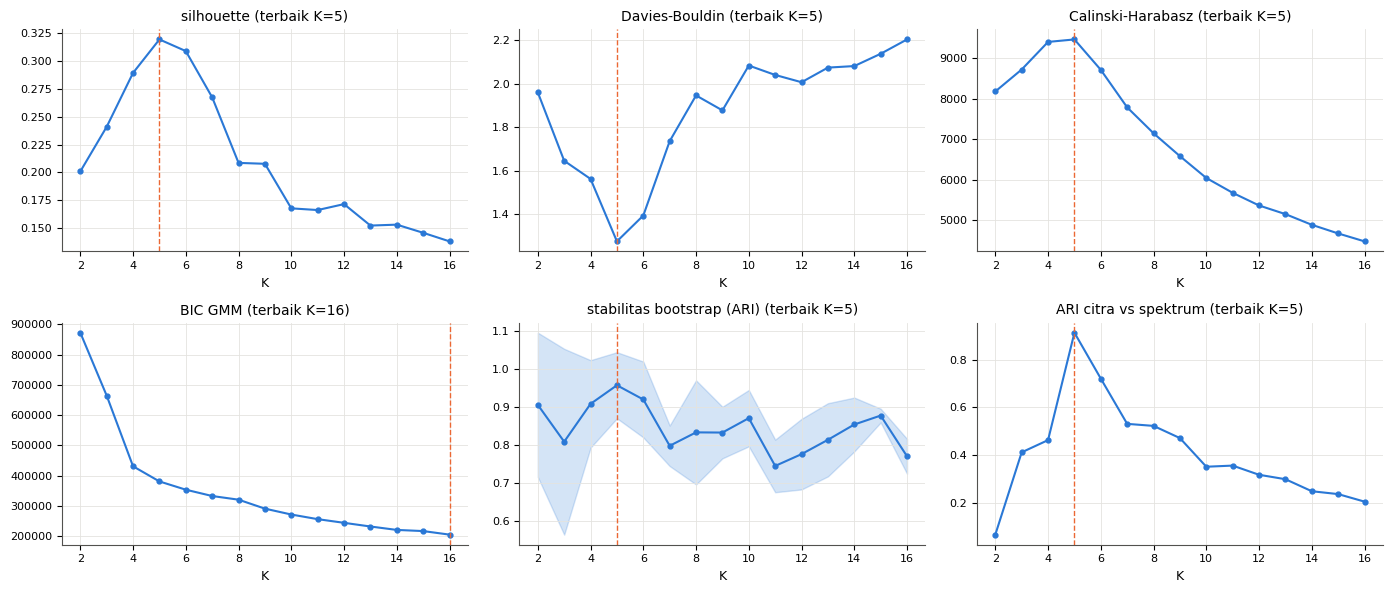

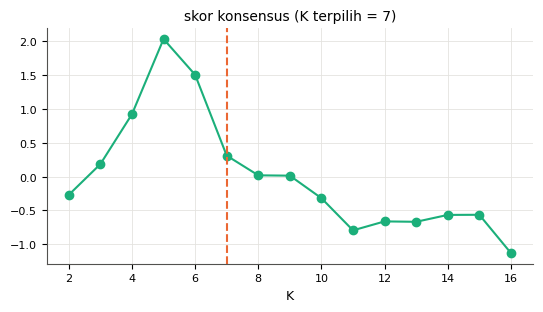

In [38]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
panels = [("silhouette", "silhouette", "max"), ("davies_bouldin", "Davies-Bouldin", "min"), ("calinski_harabasz", "Calinski-Harabasz", "max"),
          ("bic_gmm", "BIC GMM", "min"), ("stability", "stabilitas bootstrap (ARI)", "max"), ("xmodal_ari", "ARI citra vs spektrum", "max")]
for a, (col, ttl, d_) in zip(ax.ravel(), panels):
    a.plot(crit.k, crit[col], marker="o", ms=3.5, color=SERIES[0])
    if col == "stability": a.fill_between(crit.k, crit[col] - crit.stability_sd, crit[col] + crit.stability_sd, alpha=.2, color=SERIES[0])
    a.axvline(best_by[col], color=SERIES[1], ls="--", lw=1); a.set_title(f"{ttl} (terbaik K={best_by[col]})"); a.set_xlabel("K")
plt.tight_layout(); savefig(fig, "t3_k_criteria")
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(crit.k, crit.consensus_score, marker="o", color=SERIES[2]); ax.axvline(K_FINAL, color=SERIES[1], ls="--")
ax.set_title(f"skor konsensus (K terpilih = {K_FINAL})"); ax.set_xlabel("K")
plt.tight_layout(); savefig(fig, "t3_k_consensus")

### Pemeriksaan tambahan: struktur graf kNN

Silhouette dan Davies-Bouldin menilai cluster yang bulat di sekitar centroid, sehingga dua kelompok yang berdekatan bisa dianggap satu.
Dua ukuran berikut tidak bergantung pada bentuk bulat:

* **Komponen terhubung** graf k tetangga terdekat: kelompok yang benar-benar terpisah menjadi komponen sendiri.
* **Eigengap** Laplacian ternormalisasi: bila ada K kelompok yang terpisah baik, K eigenvalue pertama hampir nol dan eigenvalue ke K+1 melompat.

Hasilnya hanya informasi tambahan dan tidak masuk skor konsensus. Bila menunjuk K yang berbeda dari konsensus, isi `K_OVERRIDE` pada sel konfigurasi lalu jalankan ulang dari bagian 7.

k=15: komponen terhubung = 5, ukuran = [10043, 8685, 8637, 4979, 3656]
   eigenvalue terkecil: [-0.0, -0.0, 0.0, 0.0, 0.0016, 0.0031, 0.0311, 0.0374, 0.0381, 0.0382, 0.0415, 0.0421]
   K dengan eigengap terbesar: [14, 6, 16] [0.0359, 0.0279, 0.0223]
k=30: komponen terhubung = 5, ukuran = [10043, 8685, 8637, 4979, 3656]
   eigenvalue terkecil: [-0.0, -0.0, -0.0, -0.0, 0.0024, 0.0047, 0.039, 0.0465, 0.0483, 0.0484, 0.0517, 0.0522]
   K dengan eigengap terbesar: [14, 6, 16] [0.0473, 0.0343, 0.0247]


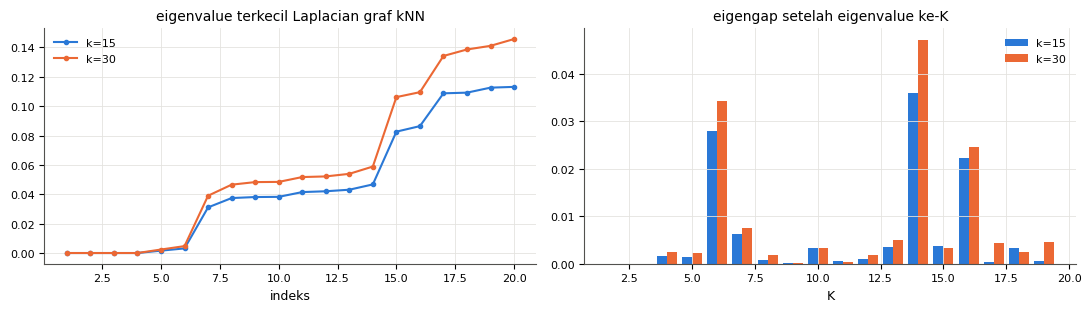

In [39]:
from scipy.sparse import csgraph, diags
from scipy.sparse.linalg import eigsh

def knn_graph_spectrum(Xin, k=30, n_eig=20):
    A = kneighbors_graph(Xin, k, include_self=False, mode="connectivity"); A = ((A + A.T) > 0).astype(float).tocsr()
    n_comp, comp = csgraph.connected_components(A, directed=False)
    d = np.asarray(A.sum(1)).ravel(); Dm = diags(1 / np.sqrt(d)); An = Dm @ A @ Dm        # adjacency ternormalisasi
    mu = np.sort(eigsh(An, k=n_eig, which="LA", return_eigenvectors=False))[::-1]
    lam = 1 - mu                                                                        # eigenvalue Laplacian ternormalisasi, naik
    gap = {K: float(lam[K] - lam[K - 1]) for K in range(2, n_eig)}                      # celah setelah eigenvalue ke-K
    return int(n_comp), np.bincount(comp), lam, gap

EIG = {}
for kk in (15, 30):
    n_comp, sizes, lam, gap = knn_graph_spectrum(X, k=kk)
    top = sorted(gap, key=gap.get, reverse=True)[:3]
    EIG[kk] = dict(n_components=n_comp, component_sizes=sorted(sizes.tolist(), reverse=True), eigenvalues=[float(v) for v in lam], top_k_by_gap=top, gaps=gap)
    print(f"k={kk}: komponen terhubung = {n_comp}, ukuran = {EIG[kk]['component_sizes']}")
    print("   eigenvalue terkecil:", np.round(lam[:12], 4).tolist())
    print("   K dengan eigengap terbesar:", top, [round(gap[t], 4) for t in top])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for kk, c in zip(EIG, SERIES):
    ax[0].plot(range(1, len(EIG[kk]["eigenvalues"]) + 1), EIG[kk]["eigenvalues"], marker="o", ms=3, color=c, label=f"k={kk}")
    ax[1].bar(np.array(list(EIG[kk]["gaps"])) + (0.2 if kk == 30 else -0.2), list(EIG[kk]["gaps"].values()), width=0.4, color=c, label=f"k={kk}")
ax[0].set_title("eigenvalue terkecil Laplacian graf kNN"); ax[0].set_xlabel("indeks"); ax[0].legend()
ax[1].set_title("eigengap setelah eigenvalue ke-K"); ax[1].set_xlabel("K"); ax[1].legend()
plt.tight_layout(); savefig(fig, "t3_k_eigengap")
RESULTS["k_selection_knn_graph"] = {str(kk): {k_: v for k_, v in d.items() if k_ != "gaps"} for kk, d in EIG.items()}

## 7b. Perbandingan metode clustering pada K terpilih (butir d)

Tiap metode dijalankan dengan tiga seed (metode deterministik hanya sekali). Selain silhouette pada ruang fusi, label dinilai di ruang citra
dan ruang spektrum secara terpisah. Label yang benar-benar mencerminkan jenis material seharusnya koheren di kedua ruang, jadi
rata-rata kedua silhouette itu dipakai sebagai **skor konsistensi** untuk memilih metode akhir. Ini tidak memakai label sama sekali.

Kolom `knn_cut` mengukur porsi 30 tetangga terdekat suatu titik (di ruang fusi) yang berada di cluster lain. Nilainya tinggi bila sebuah potongan menembus daerah padat,
misalnya ketika metode berbasis centroid membelah satu blob kontinu menjadi dua. Metode akhir dipilih dari `knn_cut` terendah, lalu skor konsistensi.

In [40]:
METHODS = ["kmeans", "gmm", "agglomerative", "graph", "dec"]
NN30 = NearestNeighbors(n_neighbors=31).fit(X).kneighbors(X, return_distance=False)[:, 1:]   # tetangga di ruang fusi
LABELS = {}; rows = []
for name in METHODS:
    seeds_ = SEEDS if name not in ("agglomerative", "graph") else (SEEDS[0],)
    labs = []
    for sd in seeds_:
        t0 = time.time(); labs.append(relabel_by_size(run_method(name, X, K_FINAL, sd)))
        print(f"{name:14s} seed {sd}  {time.time() - t0:5.1f}s  ukuran cluster: {np.bincount(labs[-1], minlength=K_FINAL).tolist()}")
    LABELS[name] = labs
    pair_ari = [adjusted_rand_score(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))]
    L = labs[0]
    s_f = silhouette_score(X[SIL_IDX], L[SIL_IDX]); s_i = silhouette_score(EMB["img"][SIL_IDX], L[SIL_IDX]); s_s = silhouette_score(EMB["spec"][SIL_IDX], L[SIL_IDX])
    rows.append(dict(method=name, silhouette_fused=s_f, silhouette_img_space=s_i, silhouette_spec_space=s_s, consistency=(s_i + s_s) / 2,
                     davies_bouldin=davies_bouldin_score(X, L), knn_cut=float(np.mean(L[NN30] != L[:, None])), seed_stability_ari=float(np.mean(pair_ari)) if pair_ari else np.nan))
METHOD_TABLE = pd.DataFrame(rows).set_index("method")
ref = LABELS["kmeans"][0]
METHOD_TABLE["ari_vs_kmeans"] = [adjusted_rand_score(ref, LABELS[m][0]) for m in METHOD_TABLE.index]
print(); print(METHOD_TABLE.round(3).to_string())
# Aturan pemilihan (tanpa label): (1) knn_cut terendah, yaitu porsi 30 tetangga terdekat yang berada di cluster lain, dibulatkan 2 desimal
# supaya selisih < 0,01 dianggap sama (potongan yang menembus daerah padat berarti cluster tidak nyata); (2) skor konsistensi (dibulatkan 3 desimal);
# (3) stabilitas antar seed; seri terakhir mengikuti urutan METHODS.
FINAL_METHOD = max(METHOD_TABLE.index, key=lambda m_: (-round(float(METHOD_TABLE.loc[m_, "knn_cut"]), 2),
                                                       round(float(METHOD_TABLE.loc[m_, "consistency"]), 3),
                                                       1.0 if np.isnan(METHOD_TABLE.loc[m_, "seed_stability_ari"]) else float(METHOD_TABLE.loc[m_, "seed_stability_ari"])))
print("\nmetode akhir (knn_cut terendah, lalu konsistensi):", FINAL_METHOD)
RESULTS["method_table"] = METHOD_TABLE.round(4).reset_index().to_dict("records"); RESULTS["final_method"] = FINAL_METHOD

kmeans         seed 0    1.1s  ukuran cluster: [10043, 4979, 4471, 4342, 4295, 4214, 3656]
kmeans         seed 1    1.1s  ukuran cluster: [10043, 4979, 4611, 4342, 4295, 4074, 3656]
kmeans         seed 2    1.3s  ukuran cluster: [10043, 4979, 4484, 4342, 4295, 4201, 3656]
gmm            seed 0    3.7s  ukuran cluster: [8685, 5781, 4979, 4339, 4298, 4262, 3656]
gmm            seed 1    5.8s  ukuran cluster: [8685, 5158, 4979, 4885, 4339, 4298, 3656]
gmm            seed 2    6.0s  ukuran cluster: [10043, 4979, 4507, 4339, 4298, 4178, 3656]


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_agglomerative.py:325: UserWarning: the number of connected components of the connectivity matrix is 5 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


agglomerative  seed 0   38.6s  ukuran cluster: [8685, 5790, 4979, 4341, 4296, 4253, 3656]
graph          seed 0   10.8s  ukuran cluster: [8685, 5779, 4979, 4337, 4300, 4264, 3656]
dec            seed 0    5.7s  ukuran cluster: [8685, 5757, 4979, 4324, 4313, 4286, 3656]
dec            seed 1    5.7s  ukuran cluster: [8637, 5769, 4979, 4723, 4274, 3962, 3656]
dec            seed 2    5.6s  ukuran cluster: [10043, 4979, 4677, 4335, 4302, 4008, 3656]

               silhouette_fused  silhouette_img_space  silhouette_spec_space  consistency  davies_bouldin  knn_cut  seed_stability_ari  ari_vs_kmeans
method                                                                                                                                               
kmeans                    0.267                 0.245                  0.156        0.200           1.736    0.016               0.929          1.000
gmm                       0.246                 0.228                  0.125        0.176         

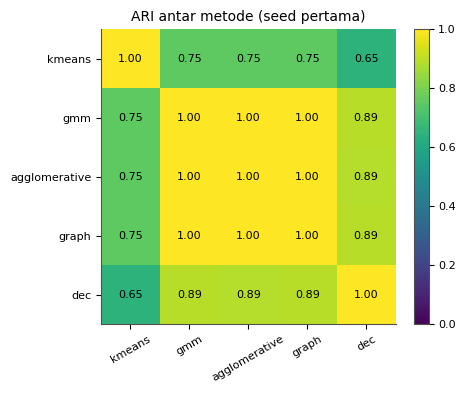

In [41]:
# Matriks ARI antar metode
names = METHODS; M = np.array([[adjusted_rand_score(LABELS[a][0], LABELS[b][0]) for b in names] for a in names])
fig, ax = plt.subplots(figsize=(4.8, 4.0)); im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis"); ax.grid(False)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w" if M[i, j] < .6 else "k", fontsize=8)
ax.set_title("ARI antar metode (seed pertama)"); plt.colorbar(im, fraction=.046); plt.tight_layout(); savefig(fig, "t3_method_ari")

In [42]:
# Uji robustness (opsional): latih ulang seluruh pipeline dengan seed lain dan bandingkan label akhir (KMeans pada embedding fusi terpilih)
FINAL_LABELS = LABELS[FINAL_METHOD][0]
if FINAL_LABELS.max() + 1 != K_FINAL:   # metode berbasis centroid kadang menghasilkan cluster kosong
    print(f"PERHATIAN: metode {FINAL_METHOD} hanya menghasilkan {FINAL_LABELS.max() + 1} cluster dari K={K_FINAL} yang diminta.")
    K_FINAL = int(FINAL_LABELS.max() + 1)
if RUN_EXTRA_SSL_SEEDS:
    pipe = {}
    for sd in SEEDS[1:]:
        ei, zi, _ = get_ssl("img", sd); es, zs, _ = get_ssl("spec", sd)
        zj, _ = get_joint(sd, ei, es)
        Xs_ = np.hstack([reduce(zi), reduce(zs)]) if FUSION_CHOICE == "concat" else reduce(zj)
        pipe[sd] = relabel_by_size(KMeans(K_FINAL, n_init=10, random_state=sd).fit_predict(Xs_))
    base = relabel_by_size(KMeans(K_FINAL, n_init=10, random_state=MAIN_SEED).fit_predict(X))
    RESULTS["pipeline_seed_ari_vs_main"] = {int(sd): float(adjusted_rand_score(base, l)) for sd, l in pipe.items()}
    print("ARI pipeline seed lain terhadap seed utama:", RESULTS["pipeline_seed_ari_vs_main"])
else:
    print("RUN_EXTRA_SSL_SEEDS = False: uji robustness lintas seed pelatihan encoder dilewati.")

RUN_EXTRA_SSL_SEEDS = False: uji robustness lintas seed pelatihan encoder dilewati.


## 8. Visualisasi dan analisis (butir f)

UMAP (seluruh sampel) dan t-SNE (subset 8.000 titik) dipakai untuk melihat struktur embedding. Cluster yang sulit dipisah dicari dengan dua cara:

1. **Tumpang tindih tetangga:** untuk tiap pasangan cluster, rata-rata porsi 30 tetangga terdekat suatu titik yang berada di cluster pasangannya.
2. **Keterpisahan per modalitas (d'):** proyeksikan titik kedua cluster ke garis antar centroid pada ruang citra dan ruang spektrum,
   lalu hitung selisih rata-rata dibagi sebaran gabungan. Nilai d' besar di satu modalitas berarti pasangan itu dipisahkan oleh modalitas tersebut.

UMAP selesai (161s)


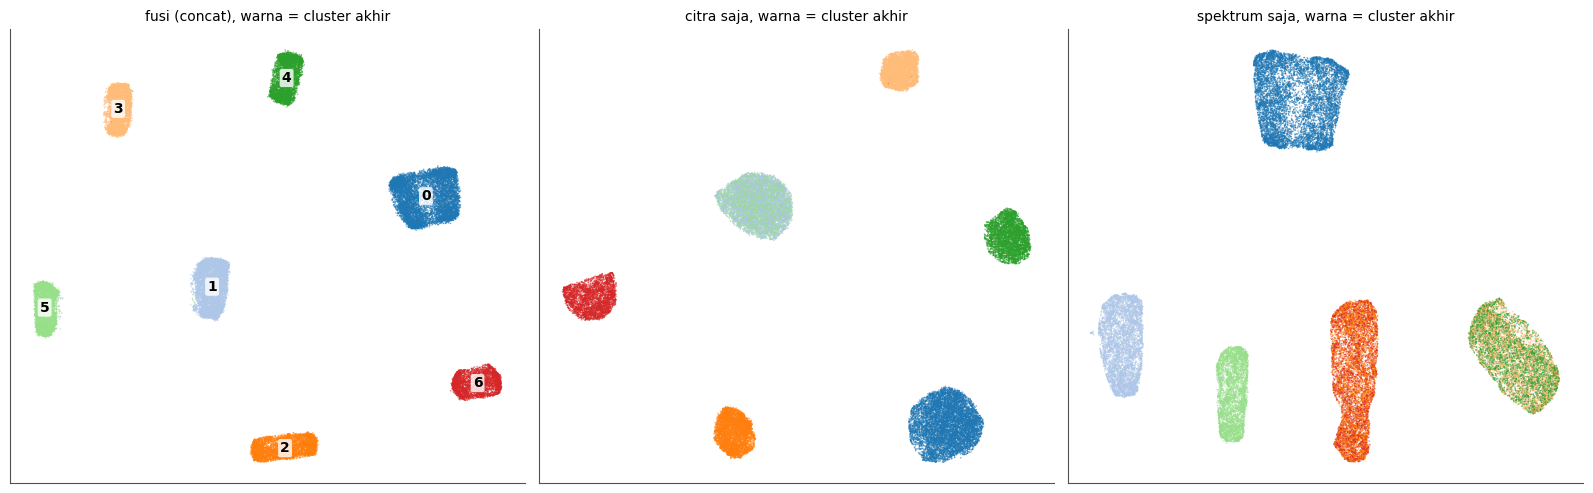

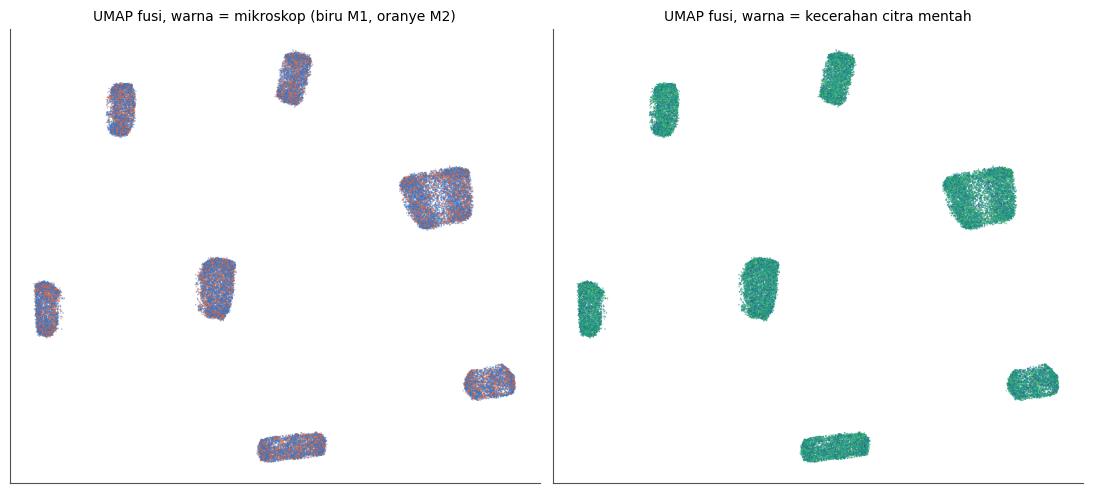

In [43]:
t0 = time.time()
UM = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(X)
UM_I = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(EMB["img"])
UM_S = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(EMB["spec"])
print(f"UMAP selesai ({time.time() - t0:.0f}s)")
cols = cat_colors(K_FINAL); L = FINAL_LABELS
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, U, ttl in [(ax[0], UM, f"fusi ({FUSION_CHOICE}), warna = cluster akhir"), (ax[1], UM_I, "citra saja, warna = cluster akhir"), (ax[2], UM_S, "spektrum saja, warna = cluster akhir")]:
    a.scatter(U[:, 0], U[:, 1], c=[cols[l] for l in L], s=1.2, alpha=.6, linewidths=0); a.set_title(ttl); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    if a is ax[0]:
        for c in range(K_FINAL):
            m = np.median(U[L == c], 0); a.text(m[0], m[1], str(c), fontsize=10, weight="bold", ha="center", va="center",
                                                bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.8))
plt.tight_layout(); savefig(fig, "t3_umap_clusters")

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(UM[:, 0], UM[:, 1], c=[MIC_COLOR[m] for m in MIC], s=1.2, alpha=.5, linewidths=0); ax[0].set_title("UMAP fusi, warna = mikroskop (biru M1, oranye M2)")
ax[1].scatter(UM[:, 0], UM[:, 1], c=img_mean, s=1.2, alpha=.6, cmap="viridis", linewidths=0); ax[1].set_title("UMAP fusi, warna = kecerahan citra mentah")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.tight_layout(); savefig(fig, "t3_umap_microscope")

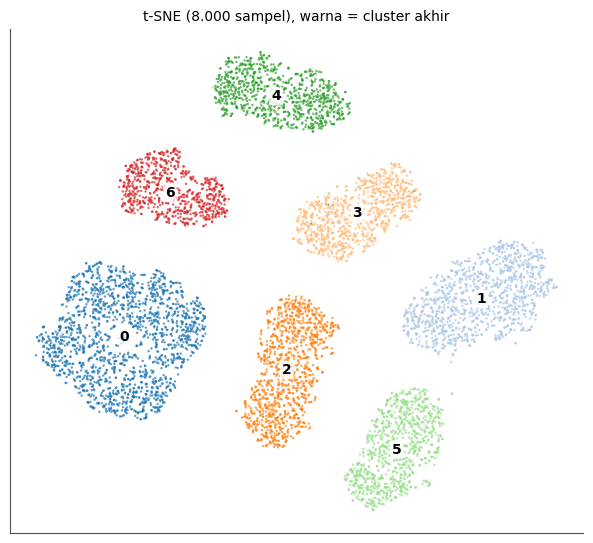

In [44]:
sub = np.random.default_rng(0).choice(N, min(8000, N), replace=False)
TS = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(PCA(min(30, X.shape[1]), random_state=0).fit_transform(X[sub]))
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(TS[:, 0], TS[:, 1], c=[cols[l] for l in L[sub]], s=3, alpha=.7, linewidths=0)
for c in range(K_FINAL):
    m = np.median(TS[L[sub] == c], 0); ax.text(m[0], m[1], str(c), fontsize=10, weight="bold", ha="center", va="center", bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.8))
ax.set_title("t-SNE (8.000 sampel), warna = cluster akhir"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); savefig(fig, "t3_tsne_clusters")

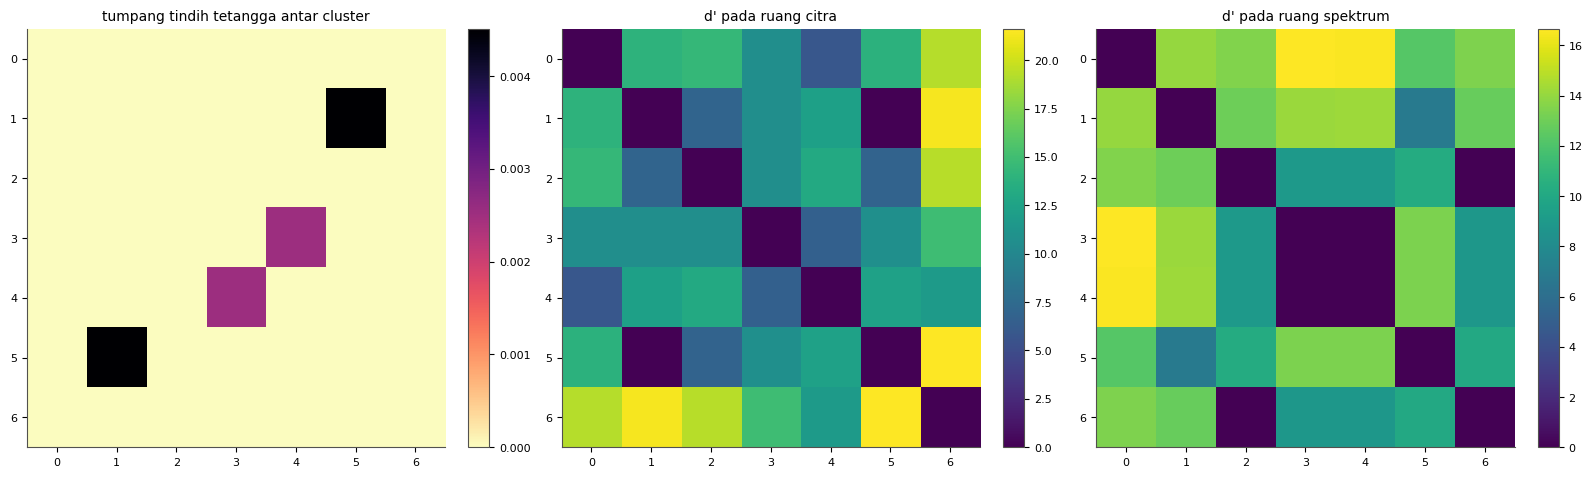

Pasangan cluster paling sulit dipisah:
  cluster 1 vs 5: tumpang tindih 0.5%, d' citra 0.06, d' spektrum 6.77  -> dipisahkan terutama oleh: spektrum
  cluster 3 vs 4: tumpang tindih 0.3%, d' citra 6.64, d' spektrum 0.06  -> dipisahkan terutama oleh: citra
  cluster 5 vs 6: tumpang tindih 0.0%, d' citra 21.62, d' spektrum 10.02  -> dipisahkan terutama oleh: citra
  cluster 4 vs 6: tumpang tindih 0.0%, d' citra 11.79, d' spektrum 8.82  -> dipisahkan terutama oleh: citra
  cluster 4 vs 5: tumpang tindih 0.0%, d' citra 12.37, d' spektrum 13.37  -> dipisahkan terutama oleh: spektrum

            n  silhouette  porsi_M2  tetangga_di_cluster_sama
cluster                                                      
0        8685       0.301     0.391                     1.000
1        5790       0.116     0.401                     0.995
2        4979       0.329     0.402                     1.000
3        4341       0.232     0.399                     0.997
4        4296       0.224     0.401       

In [45]:
# Cluster yang sulit dipisah
NB = 30
nn_idx = NearestNeighbors(n_neighbors=NB + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
CONF = np.zeros((K_FINAL, K_FINAL))
for c in range(K_FINAL):
    CONF[c] = np.bincount(L[nn_idx[L == c]].ravel(), minlength=K_FINAL) / (np.sum(L == c) * NB)

def dprime(E, a, b):
    ca, cb = E[L == a], E[L == b]; d = cb.mean(0) - ca.mean(0); n_ = np.linalg.norm(d)
    if n_ < 1e-9: return 0.0
    u = d / n_; pa, pb = ca @ u, cb @ u
    return float(abs(pb.mean() - pa.mean()) / np.sqrt(0.5 * (pa.var() + pb.var()) + 1e-12))

DP = {k_: np.zeros((K_FINAL, K_FINAL)) for k_ in ("img", "spec", "fused")}
for a in range(K_FINAL):
    for b in range(a + 1, K_FINAL):
        for k_, E in (("img", EMB["img"]), ("spec", EMB["spec"]), ("fused", X)):
            DP[k_][a, b] = DP[k_][b, a] = dprime(E, a, b)
OVER = (CONF + CONF.T) / 2; np.fill_diagonal(OVER, 0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (M_, ttl, cm) in zip(ax, [(OVER, "tumpang tindih tetangga antar cluster", "magma_r"), (DP["img"], "d' pada ruang citra", "viridis"), (DP["spec"], "d' pada ruang spektrum", "viridis")]):
    im = a.imshow(M_, cmap=cm); a.grid(False); a.set_title(ttl); a.set_xticks(range(K_FINAL)); a.set_yticks(range(K_FINAL)); plt.colorbar(im, ax=a, fraction=.046)
plt.tight_layout(); savefig(fig, "t3_pair_matrices")

pairs = sorted([(OVER[a, b], a, b) for a in range(K_FINAL) for b in range(a + 1, K_FINAL)], reverse=True)[:min(5, K_FINAL * (K_FINAL - 1) // 2)]
hard = []
print("Pasangan cluster paling sulit dipisah:")
for ov, a, b in pairs:
    di, ds = DP["img"][a, b], DP["spec"][a, b]
    who = "keduanya lemah" if max(di, ds) < 2 else ("citra" if di > ds else "spektrum")
    print(f"  cluster {a} vs {b}: tumpang tindih {ov:.1%}, d' citra {di:.2f}, d' spektrum {ds:.2f}  -> dipisahkan terutama oleh: {who}")
    hard.append(dict(a=int(a), b=int(b), overlap=float(ov), dprime_img=float(di), dprime_spec=float(ds), separated_by=who))
RESULTS["hard_pairs"] = hard

sil_samples = silhouette_samples(X[SIL_IDX], L[SIL_IDX])
cl_table = pd.DataFrame({"cluster": range(K_FINAL), "n": np.bincount(L, minlength=K_FINAL),
                         "silhouette": [sil_samples[L[SIL_IDX] == c].mean() if (L[SIL_IDX] == c).any() else np.nan for c in range(K_FINAL)],
                         "porsi_M2": [float((MIC[L == c] == "M2").mean()) for c in range(K_FINAL)],
                         "tetangga_di_cluster_sama": np.diag(CONF)}).set_index("cluster")
print(); print(cl_table.round(3).to_string())
RESULTS["cluster_table"] = cl_table.round(4).reset_index().to_dict("records")

In [46]:
# Distribusi mikroskop per cluster (uji bahwa cluster tidak sekadar mengikuti mikroskop)
from scipy.stats import chi2_contingency
ct = pd.crosstab(L, MIC); chi2, pval, _, _ = chi2_contingency(ct)
cramers_v = float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))
print(f"Cramer's V antara cluster dan mikroskop = {cramers_v:.3f} (0 = tidak ada hubungan, 1 = identik)")
RESULTS["microscope_vs_cluster_cramers_v"] = cramers_v

Cramer's V antara cluster dan mikroskop = 0.010 (0 = tidak ada hubungan, 1 = identik)


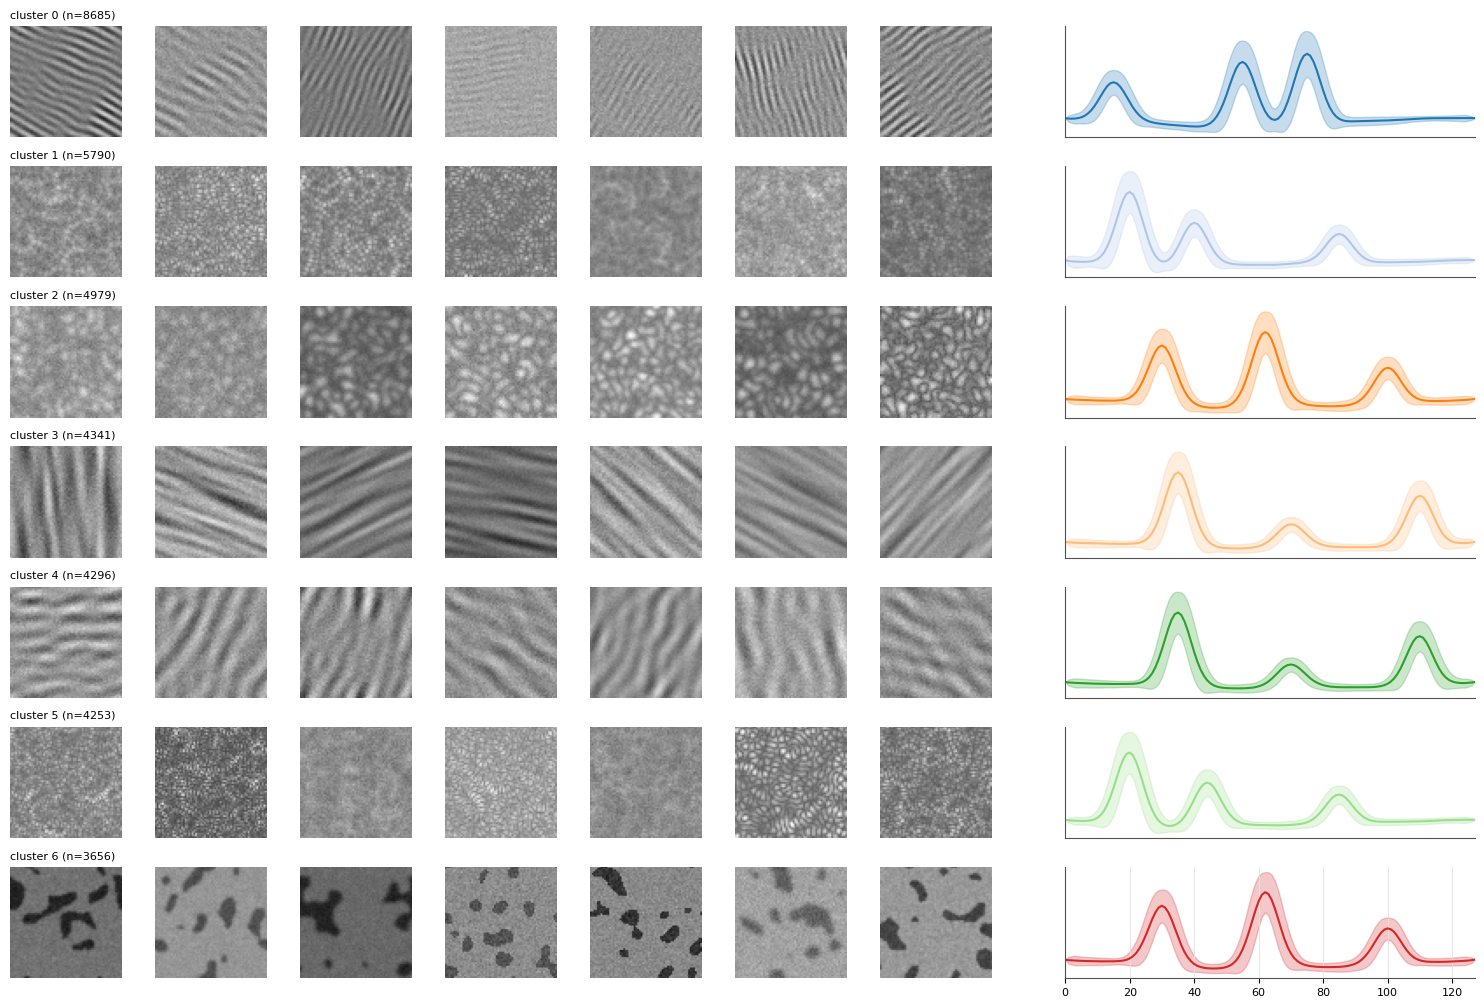

In [47]:
# Profil tiap cluster: contoh citra dan spektrum rata-rata (terpraproses)
nshow = 7; rng = np.random.default_rng(3)
fig = plt.figure(figsize=(15, 1.45 * K_FINAL))
gs = fig.add_gridspec(K_FINAL, nshow + 2, width_ratios=[1] * nshow + [0.25, 3.2])
for c in range(K_FINAL):
    idx = rng.choice(np.where(L == c)[0], min(nshow, int((L == c).sum())), replace=False)
    for j, i in enumerate(idx):
        a = fig.add_subplot(gs[c, j]); a.imshow(G_RAW[i], cmap="gray", vmin=0, vmax=255); a.axis("off")
        if j == 0: a.set_title(f"cluster {c} (n={int((L == c).sum())})", fontsize=8, loc="left")
    a = fig.add_subplot(gs[c, nshow + 1]); mu = S_PRE[L == c].mean(0); sd = S_PRE[L == c].std(0)
    a.plot(mu, color=cols[c]); a.fill_between(np.arange(128), mu - sd, mu + sd, color=cols[c], alpha=.25); a.set_yticks([]); a.set_xlim(0, 127)
    if c < K_FINAL - 1: a.set_xticks([])
plt.tight_layout(); savefig(fig, "t3_cluster_profiles")

**Cara membaca hasil bagian 8** (isi interpretasi untuk laporan setelah notebook dijalankan):

* *Cluster yang sulit dipisah* ada pada daftar pasangan di atas. Lihat kolom "dipisahkan terutama oleh". Bila d' kecil di kedua modalitas,
  dua cluster itu secara fisik mirip di citra dan di spektrum, sehingga pemisahannya kemungkinan hanya sebagian benar.
* *Efek mikroskop* dinilai dari Cramer's V dan plot UMAP berwarna mikroskop. Nilai V kecil dan warna M1/M2 yang bercampur berarti
  embedding tidak memisahkan cluster berdasarkan mikroskop.
* *Profil cluster* menunjukkan tekstur citra dan bentuk spektrum tiap cluster. Cluster yang spektrumnya sama tetapi teksturnya berbeda
  (atau sebaliknya) menunjukkan modalitas mana yang menentukan pemisahan.

## 9. Berkas keluaran

In [48]:
out = pd.DataFrame({"id_sampel": META["id_sampel"].values, "cluster": FINAL_LABELS.astype(int)})
assert len(out) == N and out["id_sampel"].is_unique and out["cluster"].dtype.kind == "i"
if not FAST:
    assert N == 36000, f"jumlah baris harus 36000, ditemukan {N}"
out.to_csv(CSV_PATH, index=False)
RESULTS["final"] = dict(k=K_FINAL, method=FINAL_METHOD, fusion=FUSION_CHOICE, cluster_sizes=np.bincount(FINAL_LABELS, minlength=K_FINAL).tolist(),
                        n=int(N), seed=MAIN_SEED, fast_mode=FAST)
RESULTS["env"] = dict(python=sys.version.split()[0], torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__,
                      sklearn=sklearn.__version__, umap=umap.__version__, device=str(DEV))
with open(OUT_DIR / "results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("ditulis:", CSV_PATH, f"({len(out)} baris)")
print("ditulis:", OUT_DIR / "results.json")
print(out.head().to_string(index=False)); print(out.cluster.value_counts().sort_index().to_string())

ditulis: /content/task3_out/task3/cluster.csv (36000 baris)
ditulis: /content/task3_out/task3/results.json
id_sampel  cluster
  S966119        3
  S315633        0
  S805122        5
  S467543        0
  S475842        0
cluster
0    8685
1    5790
2    4979
3    4341
4    4296
5    4253
6    3656


In [49]:
# Mengirim keluaran ke komputer Anda dari runtime remote.
if IN_COLAB and not FAST:
    try:
        from google.colab import files
        files.download(str(CSV_PATH))
    except Exception as e:
        print("files.download tidak tersedia di lingkungan ini:", type(e).__name__, "- pakai payload di bawah.")

# Payload: cluster.csv + results.json (+ gambar PNG selama total <= 4 MB, urut prioritas) dalam satu zip, dicetak sebagai base64.
# Teks ini ikut tersimpan di berkas .ipynb. Di komputer lokal: python extract_outputs.py <notebook.ipynb>
if EMBED_OUTPUTS and ROOT is None:
    import io, base64, hashlib
    buf = io.BytesIO(); budget = 4_000_000; skipped = []
    with zipfile.ZipFile(buf, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(CSV_PATH, CSV_PATH.name); zf.write(OUT_DIR / "results.json", "results.json")
        first = ["t3_umap_clusters", "t3_cluster_profiles", "t3_k_criteria", "t3_pair_matrices", "t3_method_ari", "t3_fusion_kscan",
                 "t3_simclr_loss", "t3_tsne_clusters", "t3_umap_microscope", "t3_eda_microscope", "t3_eda_rotation_scale", "t3_eda_spectrum_distortions"]
        figs = sorted(FIG_DIR.glob("*.png"), key=lambda p: (first.index(p.stem) if p.stem in first else len(first), p.name))
        for p in figs:
            if buf.tell() + p.stat().st_size > budget:
                skipped.append(p.name); continue
            zf.write(p, f"figures/{p.name}")
    raw = buf.getvalue(); b64 = base64.b64encode(raw).decode()
    print(f"BEGIN_TASK3_PAYLOAD sha256={hashlib.sha256(raw).hexdigest()} bytes={len(raw)}")
    for k in range(0, len(b64), 120):
        print(b64[k:k + 120])
    print("END_TASK3_PAYLOAD")
    if skipped:
        print(f"gambar tidak disertakan (melewati batas 4 MB): {len(skipped)} berkas; unduh dari {FIG_DIR} bila perlu")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

BEGIN_TASK3_PAYLOAD sha256=1c8cc01ea95f73e2d9677e596b1c27e812053211be2d36ded215fb184cd6c852 bytes=3960658
...
dXMucG5nUEsFBgAAAAASABIAFwUAACVqPAAAAA==
END_TASK3_PAYLOAD
gambar tidak disertakan (melewati batas 4 MB): 2 berkas; unduh dari /content/task3_out/task3/figures bila perlu
